## Partie **Health** 
Le projet consiste à retrouver le narratif caché dans les données. Chaque domaine détient un fragment. Pour le domaine **Health**, la question est :

> *Y a-t-il, parmi les 240 patients, un sous-groupe au profil physiologique atypique, et que disent les autres tables (signaux, notes, procédures) de ce sous-groupe ?*

Le plan suit le cours : **nettoyer et comprendre** → **représenter, comparer, réduire, regrouper** → **motifs et anomalies** → **graphes et processus**.

## 0. Résumé des résultats

*(Chaque point est démontré dans la section indiquée ; les chiffres sont recalculés par le notebook.)*

1. **Données** : les problèmes de qualité (doublons exacts, formats de dates mixtes, casse/espaces, valeurs numériques écrites en texte) sont mesurés puis traités avec justification.
2. **Un groupe de 10 patients au profil complet** : écart de pouls apical/périphérique, pic thoracique secondaire, balancement latéral avec équilibre préservé, suivi oculaire atypique, incohérences d'identification caméra/thermique. Il est retrouvé par **des voies de natures différentes** : règle à 5 critères, PCA/t-SNE, K-means, Ward, DBSCAN, Isolation Forest/ABOD, communauté Louvain.
3. **Signaux cardiaques** : 6 de ces 10 patients ont un enregistrement où les deux canaux battent **à deux rythmes réguliers mais différents** (signature d'un double rythme), ce qui les distingue d'un bruit de capteur ou d'une arythmie synchrone.
4. **L'« augmentation du déclenchement du protocole biométrique » est un artefact** de construction : ces mesures sont rattachées à la **dernière consultation** de chaque patient.
5. **Deuxième groupe, distinct** : 8 patients (dirigeants/hauts responsables) reçoivent la procédure restreinte `MRP-42` en mode `restricted_specialist` et ont un **âge biologique ~11 ans inférieur à l'âge réel** (contre ≈ 1 an pour les autres).
6. **Pistes à transmettre aux autres groupes** : identité publique, fournitures `MTL-…`, opérateur des établissements.

## 1. Imports et chargement


In [1]:
import re, warnings, itertools, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import find_peaks
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None); pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)
plt.rcParams.update({'figure.dpi': 90, 'axes.grid': True, 'grid.alpha': .3})
SEED = 0
np.random.seed(SEED)

DATA = 'data/health/'
raw = {
    'patients':   pd.read_csv(DATA + 'patient_administration.csv'),
    'encounters': pd.read_csv(DATA + 'clinical_encounters.csv'),
    'observations': pd.read_csv(DATA + 'clinical_observations.csv'),
    'procedures': pd.read_csv(DATA + 'clinical_procedures.csv'),
    'notes':      pd.read_csv(DATA + 'clinical_notes.csv'),
    'recordings': pd.read_csv(DATA + 'cardiac_recordings.csv'),
    'samples':    pd.read_csv(DATA + 'cardiac_signal_samples.csv'),
}
prof = pd.DataFrame({k: {'lignes': v.shape[0], 'colonnes': v.shape[1],
                         'doublons exacts': int(v.duplicated().sum()),
                         'cellules manquantes': int(v.isna().sum().sum())} for k, v in raw.items()}).T
prof

,lignes,colonnes,doublons exacts,cellules manquantes
patients,241,10,1,0
encounters,1069,12,2,243
observations,17736,14,2,23933
procedures,311,14,1,317
notes,30,11,0,30
recordings,44,19,0,0
samples,96925,4,0,0


## 2. Profilage et audit qualité


In [2]:
def text_audit(df, name):
    """Espaces parasites et variantes de casse dans les colonnes texte (hors texte libre des notes)."""
    rows = []
    for c in df.columns:
        if pd.api.types.is_numeric_dtype(df[c]) or c == 'text':
            continue
        s = df[c].dropna().astype(str)
        if s.empty:
            continue
        n_space = int(((s != s.str.strip()) | s.str.contains(r'\s{2,}')).sum())
        norm = s.str.strip().str.replace(r'\s+', ' ', regex=True)
        n_case = int(norm.nunique() - norm.str.lower().nunique())
        if n_space or (n_case and norm.nunique() < 80):
            rows.append({'table': name, 'colonne': c, 'valeurs avec espaces parasites': n_space,
                         'modalités en trop (variantes de casse)': n_case})
    return rows

audit = pd.DataFrame([r for k, v in raw.items() for r in text_audit(v, k)])
display(audit)

# formats de dates : on remplace chaque chiffre par 9 pour voir les "gabarits"
def date_patterns(s):
    return s.dropna().astype(str).str.replace(r'\d', '9', regex=True).value_counts()

for tab, col in [('encounters', 'encounter_start'), ('encounters', 'encounter_end'), ('encounters', 'follow_up_date'),
                 ('patients', 'registration_date')]:
    print(f'--- {tab}.{col}'); print(date_patterns(raw[tab][col]).to_string())

,table,colonne,valeurs avec espaces parasites,modalités en trop (variantes de casse)
0,patients,family_name,1,0
1,patients,home_region,0,1
2,patients,occupation_text,2,1
3,patients,record_status,0,1
4,encounters,encounter_type,0,5
5,encounters,referral_source,0,3
6,encounters,service_unit,3,0
7,encounters,disposition,0,3
8,observations,observation_name,50,0
9,observations,interpretation_code,0,5


--- encounters.encounter_start
encounter_start
9999-99-99T99:99:99     1065
99/99/9999 99:99:99        2
99-Nov-9999 99:99:99       1
9999/99/99 99:99:99        1
--- encounters.encounter_end
encounter_end
9999-99-99T99:99:99     1065
99/99/9999 99:99:99        2
9999/99/99 99:99:99        1
99-May-9999 99:99:99       1
--- encounters.follow_up_date
follow_up_date
9999-99-99     827
9999/99/99       1
99-Apr-9999      1
--- patients.registration_date
registration_date
9999-99-99    239
99/99/9999      1
9999/99/99      1


* **Doublons exacts** : 1 patient, 2 consultations, 2 observations, 1 procédure → doublons réels (même identifiant et mêmes valeurs), à supprimer (sinon double comptage).
* **Catégories non fixes** : `encounter_type`, `referral_source`, `disposition`, `interpretation_code`, `authorization_class`… existent en `MAJUSCULES`, `Title_Case` ou avec espaces multiples ; la région `vALENNE rEPUBLIC` existe en plus de `Valenne Republic`.
* **Formats de dates mixtes** : 4 gabarits (`2021-12-28T10:15:00`, `28/12/2021 11:31:00`, `2021/05/15 13:00:00`, `19-Nov-2020 12:15:00`). Le format `jj/mm/aaaa` est **sans ambiguïté** ici (la consultation voisine confirme `28/12/2021` = 28 décembre).
* **Valeurs numériques en texte** : `numeric_value` contient `84,9` (virgule décimale) ou `24.2 index` (unité collée), déjà vu dans l'exploration initiale.

## 3. Nettoyage


In [3]:
def clean_strings(df):
    df = df.copy()
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and c != 'text':
            df[c] = df[c].str.strip().str.replace(r'\s+', ' ', regex=True)
    return df

def canon_by_mode(s):
    """Fusionne les variantes de casse vers la forme la plus fréquente."""
    key = s.str.lower()
    best = s.groupby(key).agg(lambda x: x.value_counts().index[0])
    return key.map(best)

DATE_FORMATS = ['%d/%m/%Y %H:%M:%S', '%Y/%m/%d %H:%M:%S', '%d-%b-%Y %H:%M:%S', '%d/%m/%Y', '%Y/%m/%d', '%d-%b-%Y']
def parse_dt(s):
    out = pd.to_datetime(s, format='ISO8601', errors='coerce')
    for fmt in DATE_FORMATS:
        out = out.combine_first(pd.to_datetime(s, format=fmt, errors='coerce'))
    return out

def parse_number(v):
    if pd.isna(v): return np.nan
    v = str(v).strip().replace(',', '.')
    m = re.match(r'^-?\d+\.?\d*', v)
    return float(m.group()) if m else np.nan

before = {k: len(v) for k, v in raw.items()}
admin = clean_strings(raw['patients']).drop_duplicates()
enc   = clean_strings(raw['encounters']).drop_duplicates()
obs   = clean_strings(raw['observations']).drop_duplicates()
proc  = clean_strings(raw['procedures']).drop_duplicates()
notes = raw['notes'].copy()
rec   = clean_strings(raw['recordings'])
smp   = raw['samples'].copy()

for df, cols in [(admin, ['registered_sex', 'record_status']),
                 (enc, ['encounter_type', 'referral_source', 'service_unit', 'disposition', 'confidentiality_class']),
                 (obs, ['interpretation_code', 'quality_code']),
                 (proc, ['authorization_class', 'procedure_status', 'outcome_code'])]:
    for c in cols:
        df[c] = df[c].str.lower()
admin['home_region'] = canon_by_mode(admin['home_region'])
proc['procedure_description'] = canon_by_mode(proc['procedure_description'])
proc['procedure_code'] = proc['procedure_code'].str.upper()

# dates
for c in ['encounter_start', 'encounter_end', 'follow_up_date']:
    enc[c] = parse_dt(enc[c])
admin['date_of_birth'] = pd.to_datetime(admin['date_of_birth'])
admin['registration_date'] = parse_dt(admin['registration_date'])
obs['observation_time'] = pd.to_datetime(obs['observation_time'])
for c in ['scheduled_time', 'performed_time', 'next_review_date']:
    proc[c] = pd.to_datetime(proc[c], errors='coerce')
rec['recording_date'] = pd.to_datetime(rec['recording_date'])

# valeurs numériques + noms d'observation canoniques (par code)
obs['value'] = obs['numeric_value'].apply(parse_number)
n_comma = int(obs['numeric_value'].astype(str).str.contains(',').sum())
n_unit  = int(obs['numeric_value'].astype(str).str.contains(r'[A-Za-z%]').sum())
name_by_code = obs.groupby('observation_code')['observation_name'].agg(lambda x: x.value_counts().index[0])
obs['observation_name'] = obs['observation_code'].map(name_by_code)

bilan = pd.DataFrame({'avant': before, 'après': {'patients': len(admin), 'encounters': len(enc), 'observations': len(obs),
                       'procedures': len(proc), 'notes': len(notes), 'recordings': len(rec), 'samples': len(smp)}})
bilan['supprimées'] = bilan['avant'] - bilan['après']
display(bilan)
print(f"Dates non parsées : {int(enc[['encounter_start','encounter_end']].isna().sum().sum())} | "
      f"valeurs numériques réparées : {n_comma} avec virgule, {n_unit} avec unité")
print('Régions :', admin['home_region'].value_counts().to_dict())

,avant,après,supprimées
patients,241,240,1
encounters,1069,1067,2
observations,17736,17734,2
procedures,311,310,1
notes,30,30,0
recordings,44,44,0
samples,96925,96925,0


Dates non parsées : 0 | valeurs numériques réparées : 180 avec virgule, 160 avec unité
Régions : {'Avelora Federation': 54, 'Nordhaven Union': 52, 'Valenne Republic': 48, 'Kintara Republic': 47, 'Tembara Commonwealth': 39}


### 3.1 Cohérence référentielle et valeurs aberrantes

Après le nettoyage de forme, on teste le **fond** : les liens entre tables sont-ils cohérents, et y a-t-il des valeurs impossibles ?

In [4]:
enc_pat = enc.set_index('encounter_number')['patient_number']
rows = []
for name, df in [('observations', obs), ('procedures', proc), ('notes', notes), ('recordings', rec)]:
    mapped = df['encounter_number'].map(enc_pat)
    rows.append({'table': name, 'encounter inconnue': int(mapped.isna().sum()),
                 'patient différent de celui de la consultation': int((mapped.notna() & (mapped != df['patient_number'])).sum()),
                 'patient absent de patient_administration': int((~df['patient_number'].isin(admin['patient_number'])).sum())})
display(pd.DataFrame(rows))

print('Consultations dont la fin précède le début :', int((enc['encounter_end'] < enc['encounter_start']).sum()))
print('Procédures réalisées avant la date prévue   :', int((proc['performed_time'] < proc['scheduled_time']).sum()))
first_enc = enc.groupby('patient_number')['encounter_start'].min()
reg = admin.set_index('patient_number')['registration_date']
print('Patients avec une consultation AVANT leur date d\'enregistrement :', int((first_enc < reg.reindex(first_enc.index)).sum()))

# valeurs hors plage de référence (texte "a–b")
rng = obs['reference_range_text'].str.extract(r'^\s*(-?\d+\.?\d*)\s*[–-]\s*(-?\d+\.?\d*)\s*$').astype(float)
obs['ref_lo'], obs['ref_hi'] = rng[0], rng[1]
chk = obs.dropna(subset=['value', 'ref_lo'])
out_rng = chk[(chk['value'] < chk['ref_lo']) | (chk['value'] > chk['ref_hi'])]
tab = out_rng.groupby('observation_code').size().rename('hors plage').to_frame().join(
      chk.groupby('observation_code').size().rename('mesures')).assign(part=lambda d: (d['hors plage']/d['mesures']).round(3))
display(tab.sort_values('hors plage', ascending=False).head(8))
print('Valeurs négatives impossibles :', int(((obs['value'] < 0) & ~obs['observation_code'].isin(['LEFTEYE','RIGHTEYE'])).sum()),
      '| O2SAT > 100 :', int((obs.query("observation_code=='O2SAT'")['value'] > 100).sum()))

,table,encounter inconnue,patient différent de celui de la consultation,patient absent de patient_administration
0,observations,0,0,0
1,procedures,0,0,0
2,notes,0,0,0
3,recordings,0,0,0


Consultations dont la fin précède le début : 0
Procédures réalisées avant la date prévue   : 0
Patients avec une consultation AVANT leur date d'enregistrement : 0


,hors plage,mesures,part
observation_code,,,
CARDOUT,38,941,0.040
BIOAGE,26,934,0.028
RPULSE,23,1017,0.023
PPULSE,15,1017,0.015
O2SAT,10,1017,0.010
APICAL,10,1017,0.010
STROKEVOL,2,240,0.008
SYSBP,2,240,0.008


Valeurs négatives impossibles : 0 | O2SAT > 100 : 0


**.**
* Les liens sont **cohérents** (aucun orphelin, aucune consultation attribuée à un autre patient) : on peut fusionner les tables sans risque.
* Aucune valeur physiquement impossible : on **ne supprime aucune valeur extrême**. Les valeurs hors plage de référence sont **l'objet de l'étude** (§8-10) et non du bruit.
* Aucune consultation n'a lieu avant l'enregistrement du patient et aucune fin de consultation n'est antérieure à son début : la chronologie est cohérente.

### 3.2 Valeurs manquantes : structurelles ou réelles ?


In [5]:
miss = []
def add(tab, col, n, nature, action):
    miss.append({'table': tab, 'colonne': col, 'manquants': int(n), 'nature': nature, 'décision': action})
add('observations', 'numeric_value', obs['numeric_value'].isna().sum(), 'structurel : mesures qualitatives (OCULAR, VESTIB…) stockées dans text_value', 'aucune')
add('observations', 'text_value', obs['text_value'].isna().sum(), 'structurel : mesures numériques', 'aucune')
add('observations', 'device_reference', obs['device_reference'].isna().sum(), 'réel (non renseigné)', 'colonne non utilisée')
add('encounters', 'follow_up_date', enc['follow_up_date'].isna().sum(), 'structurel : pas de suivi prévu', 'aucune (l\'absence est une information)')
add('encounters', 'referral_source', enc['referral_source'].isna().sum(), 'réel (3 lignes)', 'modalité "unknown"')
add('procedures', 'material_reference', proc['material_reference'].isna().sum(), 'structurel : seules les procédures MRP-42 consomment un matériel', 'aucune (piste logistique, §13)')
add('notes', 'superseded_document_id', notes['superseded_document_id'].isna().sum(), 'structurel : aucune note remplacée', 'colonne ignorée')
enc['referral_source'] = enc['referral_source'].fillna('unknown')
pd.DataFrame(miss)

,table,colonne,manquants,nature,décision
0,observations,numeric_value,1870,"structurel : mesures qualitatives (OCULAR, VESTIB…) stockées dans text_value",aucune
1,observations,text_value,15864,structurel : mesures numériques,aucune
2,observations,device_reference,4325,réel (non renseigné),colonne non utilisée
3,encounters,follow_up_date,240,structurel : pas de suivi prévu,aucune (l'absence est une information)
4,encounters,referral_source,3,réel (3 lignes),"modalité ""unknown"""
5,procedures,material_reference,260,structurel : seules les procédures MRP-42 consomment un matériel,"aucune (piste logistique, §13)"
6,notes,superseded_document_id,30,structurel : aucune note remplacée,colonne ignorée


## 4. Table patient, statistiques descriptives et corrélations

Choix de construction justifiés :
* `pulse_gap` = pouls **apical − périphérique** (`APICAL − PPULSE`). Les notes cliniques parlent de « discordance entre pouls périphérique et enregistrement apical », et le flag `discordant` de la base porte sur `APICAL`. L'exploration initiale utilisait `APICAL − RPULSE` (nous gardons aussi cette variante).
* `age` et `bio_gap` = âge biologique estimé **moins** âge réel **à la date de chaque mesure** (plus juste qu'un âge à date fixe).
* `n_discordant` = nombre de mesures `APICAL` marquées `discordant` par le système.
* `ocular_atyp` = part des suivis oculaires interprétés `atypical`. `binoc` = binocular coordination (0 normal, 1 reduced, 2 atypical) mesurée une seule fois par patient.
* Les rares valeurs absentes de ces agrégats sont mises à 0 pour les compteurs et à la **médiane** pour les mesures continues (choix neutre qui n'influence pas la détection d'anomalies).

In [6]:
dob = admin.set_index('patient_number')['date_of_birth']
obs['age_at_obs'] = (obs['observation_time'] - obs['patient_number'].map(dob)).dt.days / 365.25

num = obs.pivot_table(index='patient_number', columns='observation_code', values='value', aggfunc='mean')
F = pd.DataFrame(index=sorted(admin['patient_number']))
cont = ['RPULSE', 'APICAL', 'PPULSE', 'CARDOUT', 'O2SAT', 'THORVIB', 'THORPEAK', 'LATSWAY', 'BALANCE', 'BIOAGE', 'INFLAM',
        'COGNITIVE', 'MOBILITY', 'CAMMATCH', 'IDCONS', 'THERMQUAL', 'GAITSYM', 'WALKSPD', 'LEFTEYE', 'RIGHTEYE',
        'VALEFT', 'VARIGHT', 'SYSBP', 'DIABP', 'STROKEVOL', 'CVRISK', 'AGECOND']
F[cont] = num[cont]
F['pulse_gap']  = num['APICAL'] - num['PPULSE']
F['pulse_gap_rest'] = num['APICAL'] - num['RPULSE']
F['eye_asym']   = num['LEFTEYE'].abs() - num['RIGHTEYE'].abs()
F['n_discordant'] = obs[(obs.observation_code == 'APICAL') & (obs.interpretation_code == 'discordant')].groupby('patient_number').size()
F['ocular_atyp'] = obs[obs.observation_code == 'OCULAR'].groupby('patient_number')['text_value'].apply(lambda s: (s == 'atypical').mean())
F['binoc'] = obs[obs.observation_code == 'BINOCOORD'].drop_duplicates('patient_number').set_index('patient_number')['text_value'].map({'normal': 0, 'reduced': 1, 'atypical': 2})
F['age'] = obs.groupby('patient_number')['age_at_obs'].mean()
bio = obs[obs.observation_code == 'BIOAGE'].assign(gap=lambda d: d['value'] - d['age_at_obs'])
F['bio_gap'] = bio.groupby('patient_number')['gap'].mean()
for c in ['n_discordant', 'ocular_atyp', 'binoc']:
    F[c] = F[c].fillna(0)
F = F.fillna(F.median(numeric_only=True))
F = F.join(admin.set_index('patient_number')[['occupation_text', 'home_region', 'registered_sex', 'date_of_birth', 'primary_facility_license']])
print(F.shape, '| patients =', F.index.nunique())
F[['pulse_gap', 'n_discordant', 'THORVIB', 'THORPEAK', 'LATSWAY', 'BALANCE', 'ocular_atyp', 'binoc', 'CAMMATCH', 'IDCONS', 'THERMQUAL', 'bio_gap']].describe().T.round(2)

(240, 40) | patients = 240


,count,mean,std,min,25%,50%,75%,max
pulse_gap,240.0,3.37,7.39,-9.12,-1.25,2.32,5.64,30.52
n_discordant,240.0,0.45,1.29,0.00,0.00,0.00,0.00,6.00
THORVIB,240.0,29.46,14.19,0.35,19.62,28.96,37.35,76.44
THORPEAK,240.0,27.76,15.84,0.00,16.27,25.98,37.56,78.48
LATSWAY,240.0,32.18,17.03,0.00,21.58,31.50,39.30,87.72
BALANCE,240.0,76.82,12.41,44.20,68.29,77.77,85.12,100.00
ocular_atyp,240.0,0.04,0.19,0.00,0.00,0.00,0.00,1.00
binoc,240.0,0.44,0.60,0.00,0.00,0.00,1.00,2.00
CAMMATCH,240.0,89.38,9.36,40.60,84.82,91.25,95.80,100.00
IDCONS,240.0,92.19,7.15,36.30,89.80,93.20,96.45,100.00


### 4.1 Distributions : normale ou loi de puissance ?


,moyenne,médiane,écart-type,asymétrie (skew),kurtosis
pulse_gap,3.37,2.32,7.39,1.45,2.58
THORPEAK,27.76,25.98,15.84,0.61,0.22
THORVIB,29.46,28.96,14.19,0.59,0.52
LATSWAY,32.18,31.50,17.03,0.68,0.54
BALANCE,76.82,77.77,12.41,-0.15,-0.38
CAMMATCH,89.38,91.25,9.36,-1.73,4.79
IDCONS,92.19,93.20,7.15,-3.10,17.23
THERMQUAL,89.40,90.25,7.50,-0.83,1.25
bio_gap,-1.36,-1.40,5.23,0.13,-0.16


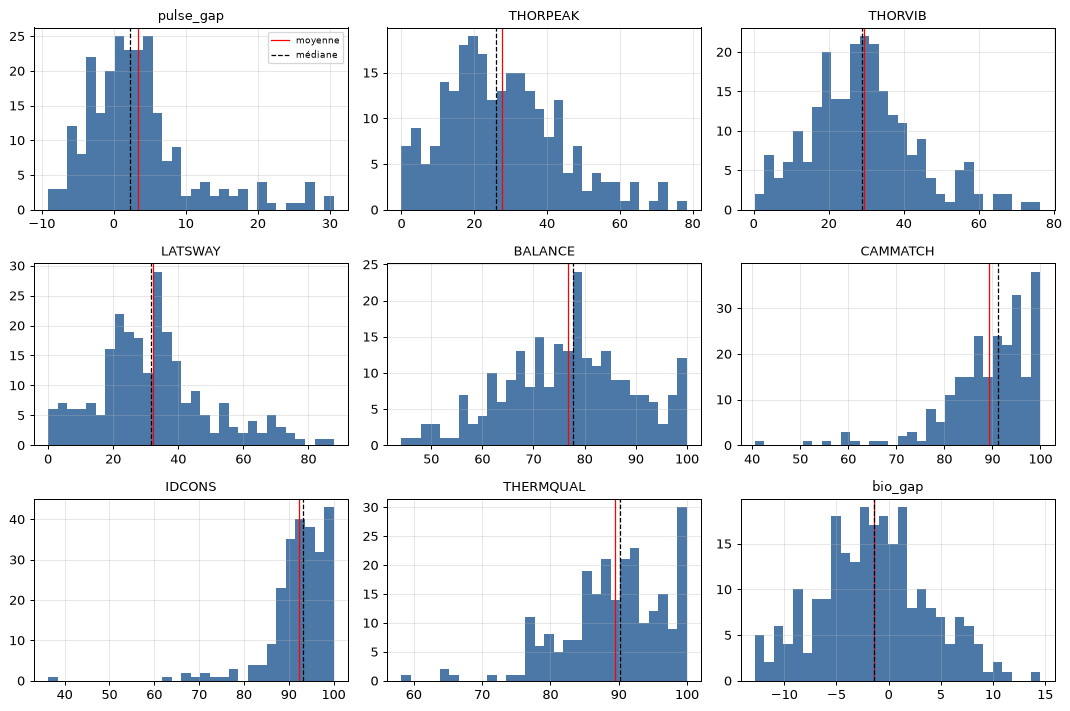

In [7]:
show = ['pulse_gap', 'THORPEAK', 'THORVIB', 'LATSWAY', 'BALANCE', 'CAMMATCH', 'IDCONS', 'THERMQUAL', 'bio_gap']
shape = pd.DataFrame({'moyenne': F[show].mean(), 'médiane': F[show].median(), 'écart-type': F[show].std(),
                      'asymétrie (skew)': F[show].skew(), 'kurtosis': F[show].kurt()}).round(2)
display(shape)
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, c in zip(axes.ravel(), show):
    ax.hist(F[c], bins=30, color='#4c78a8'); ax.axvline(F[c].mean(), color='r', lw=1, label='moyenne'); ax.axvline(F[c].median(), color='k', ls='--', lw=1, label='médiane')
    ax.set_title(c, fontsize=10)
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

**.** `pulse_gap` (asymétrie 1,45) a une nette **queue vers les valeurs élevées** ; `THORPEAK`, `THORVIB`, `LATSWAY` ont une asymétrie positive modérée (0,6 à 0,7). C'est exactement la zone où se trouve un éventuel sous-groupe atypique. `CAMMATCH`, `IDCONS`, `THERMQUAL` sont l'inverse (plafond à 100, queue vers les valeurs basses) : un score d'identification **bas** est la valeur inhabituelle. `BALANCE` est plafonné à 100 (effet de plafond).

### 4.2 Corrélations : Pearson et Spearman


In [8]:
cor_cols = ['pulse_gap', 'n_discordant', 'THORPEAK', 'THORVIB', 'LATSWAY', 'BALANCE', 'ocular_atyp', 'binoc',
            'CAMMATCH', 'IDCONS', 'THERMQUAL', 'GAITSYM', 'CARDOUT', 'bio_gap', 'age']
P = F[cor_cols].corr(method='pearson'); S = F[cor_cols].corr(method='spearman')
pairs = []
for i, j in itertools.combinations(cor_cols, 2):
    pairs.append({'var 1': i, 'var 2': j, 'Pearson': P.loc[i, j], 'Spearman': S.loc[i, j], '|écart|': abs(abs(P.loc[i, j]) - abs(S.loc[i, j]))})
pairs = pd.DataFrame(pairs)
print('Plus fortes relations (Spearman) :'); display(pairs.reindex(pairs['Spearman'].abs().sort_values(ascending=False).index).head(10).round(2))
print('Plus gros écarts Pearson / Spearman :'); display(pairs.sort_values('|écart|', ascending=False).head(6).round(2))

Plus fortes relations (Spearman) :


,var 1,var 2,Pearson,Spearman,|écart|
0,pulse_gap,n_discordant,0.83,0.55,0.28
14,n_discordant,THORPEAK,0.61,0.47,0.15
69,ocular_atyp,binoc,0.45,0.36,0.09
18,n_discordant,ocular_atyp,0.32,0.30,0.02
3,pulse_gap,LATSWAY,0.36,0.29,0.07
16,n_discordant,LATSWAY,0.35,0.27,0.08
15,n_discordant,THORVIB,0.38,0.27,0.10
1,pulse_gap,THORPEAK,0.51,0.26,0.25
85,CAMMATCH,THERMQUAL,0.37,0.24,0.12
30,THORPEAK,ocular_atyp,0.21,0.21,0.01


Plus gros écarts Pearson / Spearman :


,var 1,var 2,Pearson,Spearman,|écart|
84,CAMMATCH,IDCONS,0.46,0.18,0.28
0,pulse_gap,n_discordant,0.83,0.55,0.28
1,pulse_gap,THORPEAK,0.51,0.26,0.25
21,n_discordant,IDCONS,-0.33,-0.12,0.21
24,n_discordant,CARDOUT,0.40,0.19,0.21
8,pulse_gap,IDCONS,-0.26,-0.06,0.20


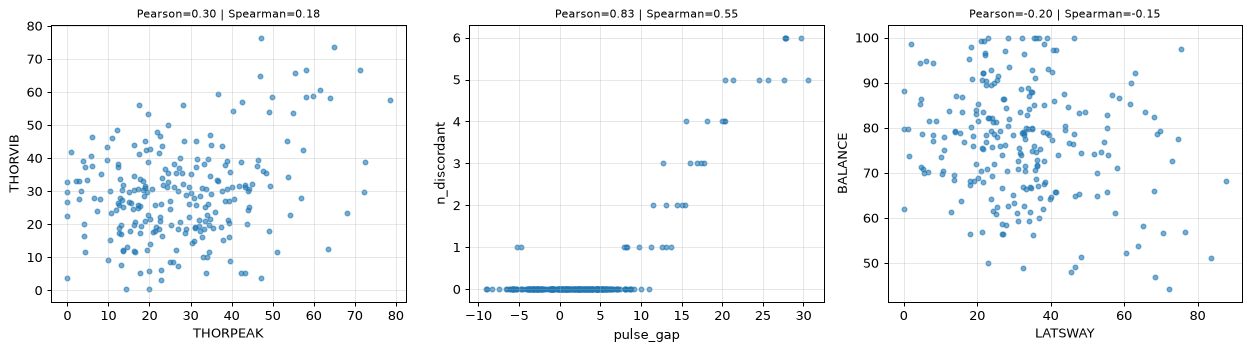

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x, y) in zip(axes, [('THORPEAK', 'THORVIB'), ('pulse_gap', 'n_discordant'), ('LATSWAY', 'BALANCE')]):
    ax.scatter(F[x], F[y], s=14, alpha=.6); ax.set_xlabel(x); ax.set_ylabel(y)
    ax.set_title(f"Pearson={F[x].corr(F[y]):.2f} | Spearman={F[x].corr(F[y], method='spearman'):.2f}", fontsize=9)
plt.tight_layout(); plt.show()

** et prudence.**
* `pulse_gap` et `n_discordant` sont très liés (Pearson 0,83) **parce que `n_discordant` est dérivé de `pulse_gap`** : le nuage de points montre une fonction en **marche d'escalier** (le système ne signale « discordant » qu'au-delà d'un écart d'environ +8 bpm). C'est une **variable calculée/redondante** (le cours conseille de retirer ce type de variable, voir §8.1). L'écart Pearson (0,83) / Spearman (0,55) montre que la relation est tirée par **quelques points extrêmes**.
* `THORPEAK` et `THORVIB` ne sont que **faiblement liés** (0,30 / 0,18) : ce ne sont pas des doublons, ils mesurent deux aspects différents du thorax.
* `LATSWAY` (balancement) et `BALANCE` (score d'équilibre) ne sont que **faiblement anti-corrélés** (−0,20) : médicalement, un fort balancement devrait dégrader l'équilibre. Les notes décrivent justement un balancement **sans perte d'équilibre** (« balance scores stay high »), ce qui est un premier indice d'un profil **inhabituel**.
* **Corrélation ≠ causalité** : ces liens décrivent des co-occurrences, pas un mécanisme.
* Dans les nuages de points, quelques patients sont **extrêmes sur plusieurs variables à la fois** (coin supérieur droit de `THORPEAK` × `THORVIB`, valeurs élevées de `pulse_gap`), ce qui motive la suite (§8-9).

## 5. Notes cliniques : texte libre

**Hypothèse** : la plupart des notes sont des gabarits répétitifs ; quelques notes réellement singulières portent l'information, et certains gabarits contiennent un **paragraphe d'exception** qui infirme un indice (cas négatifs à ne pas retenir à tort).

In [10]:
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2, sublinear_tf=True)
T = tfidf.fit_transform(notes['text'])
Sim = cosine_similarity(T); np.fill_diagonal(Sim, np.nan)
notes['sim_moyenne'] = np.nanmean(Sim, axis=1)
notes['gabarit'] = notes['text'].str.contains('Source-local patient, encounter, facility, and professional references were retained for audit')

# paragraphes d'exception ajoutés en fin de gabarit
exc = notes['text'].str.extract(r'(?:\r?\n)(DIFFERENTIAL NOTE|TECHNICAL NOTE)(?:\r?\n)(.*?)(?:\r?\n\r?\n|$)', flags=re.S)
notes['exception'] = exc[0]; notes['exception_texte'] = exc[1].str.replace(r'\s+', ' ', regex=True)

kw = {'double structure': r'dual cardiac|two (?:spatially distinct|contractile)|second(?:ary)? (?:smaller )?(?:source|contour)|independent',
      'balancement': r'sway', 'oculaire': r'ocular', 'identité / caméra': r'identity|camera|appearance control|mismatch|thermal',
      'classification': r'species|biological classification|internal designation'}
for k, rx in kw.items():
    notes[k] = notes['text'].str.count(rx, flags=re.I)
view = notes[['document_id', 'patient_number', 'document_type', 'title', 'confidentiality_class', 'gabarit', 'sim_moyenne',
              'double structure', 'balancement', 'oculaire', 'identité / caméra', 'classification', 'exception']].sort_values('sim_moyenne')
display(view.head(8).round(3))
print('Notes gabarit :', int(notes['gabarit'].sum()), '/', len(notes))
display(notes.loc[notes['exception'].notna(), ['document_id', 'patient_number', 'exception', 'exception_texte']])

,document_id,patient_number,document_type,title,confidentiality_class,gabarit,sim_moyenne,double structure,balancement,oculaire,identité / caméra,classification,exception
0,CLN-510027,PAT-31065,imaging_report,Targeted Thoracic Imaging Review,restricted,False,0.108,4,0,0,0,0,NaN
2,CLN-510025,PAT-31065,specialist_consultation,Restricted Phenotype and Public-Identity Resolution,restricted,False,0.121,2,2,1,5,2,NaN
1,CLN-510055,PAT-31115,specialist_consultation,Consultation on Recurrent Capture Discrepancies,restricted,False,0.132,2,0,1,10,1,NaN
3,CLN-510064,PAT-31012,follow_up_note,Persistent Multisystem Follow-up,confidential,False,0.133,1,1,4,1,1,NaN
10,CLN-510126,PAT-31099,imaging_report,Thoracic Imaging Report 07,confidential,False,0.264,3,0,0,0,0,DIFFERENTIAL NOTE
13,CLN-510116,PAT-31054,imaging_report,Thoracic Imaging Report 10,standard,False,0.268,1,0,0,0,0,NaN
14,CLN-510118,PAT-31190,imaging_report,Thoracic Imaging Report 11,confidential,False,0.272,1,0,0,0,0,NaN
11,CLN-510129,PAT-31136,imaging_report,Thoracic Imaging Report 08,standard,False,0.274,1,0,0,0,0,NaN


Notes gabarit : 21 / 30


,document_id,patient_number,exception,exception_texte
10,CLN-510126,PAT-31099,DIFFERENTIAL NOTE,The phrase dual cardiac structures was entered in the preliminary worksheet ...
15,CLN-510039,PAT-31103,TECHNICAL NOTE,Appearance control settings on the camera were restored to default; the prio...


**.**
* **4 notes** sortent du gabarit : leur similarité moyenne avec les autres notes est de 0,11 à 0,13, contre **0,26 et plus** pour toutes les autres (coupure nette). Elles portent les mots-clés spécifiques (double structure, balancement, suivi oculaire, incohérence caméra) bien plus que les gabarits. Elles concernent **3 patients : `PAT-31065` (2 notes), `PAT-31115`, `PAT-31012`**.
* Les notes de `PAT-31099` et `PAT-31103` contiennent chacune **un paragraphe d'exception** qui annule l'indice (« dual cardiac structures … rejected », « mismatch resolved after calibration »). Ce sont des **faux positifs volontaires** : un simple comptage de mots-clés les aurait retenus à tort. On les écarte, ce qui sera confirmé par leurs signaux et mesures (§7-9).
* Les notes elles-mêmes **refusent de conclure** (« no identity or biological classification is assigned ») : elles décrivent un phénotype, pas une espèce ni une identité. Nous respectons cette limite.

## 6. Vérification d'une hypothèse de l'exploration initiale : « le protocole biométrique se déclenche de plus en plus »

L'exploration initiale a observé que 8 codes (`IDCONS`, `CAMMATCH`, `VALEFT`, `THERMQUAL`, `BINOCOORD`, `VARIGHT`, `LEFTEYE`, `RIGHTEYE`) apparaissent dans une seule consultation par patient, avec un taux qui monte de 0 % (2017) à ~84 % (2025). Faut-il y voir un protocole déployé progressivement ? Nous testons **d'abord** une explication plus simple, un **biais de construction**.

In [11]:
per_pat = obs.groupby(['patient_number', 'observation_code']).size().unstack(fill_value=0)
panel_codes = per_pat.columns[(per_pat.max() == 1) & (per_pat.gt(0).sum() >= 0.95 * len(per_pat))].tolist()
print('Codes mesurés exactement une fois par patient (panel unique) :', panel_codes)

panel_enc = set(obs[obs.observation_code.isin(panel_codes)]['encounter_number'])
e = enc.sort_values(['patient_number', 'encounter_start']).copy()
e['rang'] = e.groupby('patient_number').cumcount() + 1
e['n_visites'] = e.groupby('patient_number')['encounter_number'].transform('count')
e['derniere'] = e['rang'] == e['n_visites']
e['panel'] = e['encounter_number'].isin(panel_enc)
e['annee'] = e['encounter_start'].dt.year

print('\nPanel selon "dernière consultation du patient" :')
display(pd.crosstab(e['derniere'], e['panel'], margins=True))
print(f"Part des panels portés par la dernière consultation : {e[e.panel]['derniere'].mean():.1%}")
yr = e.groupby('annee').agg(taux_panel_toutes=('panel', 'mean'), n=('panel', 'size'), part_dernieres=('derniere', 'mean'))
yr['taux_panel_parmi_dernieres'] = e[e.derniere].groupby('annee')['panel'].mean()
display(yr.round(2))

Codes mesurés exactement une fois par patient (panel unique) : ['AGECOND', 'BINOCOORD', 'CAMMATCH', 'CVRISK', 'DIABP', 'GAITSYM', 'IDCONS', 'LEFTEYE', 'MUSC', 'NEURO', 'RIGHTEYE', 'STROKEVOL', 'SYSBP', 'THERMQUAL', 'VALEFT', 'VARIGHT', 'VESTIB', 'WALKSPD']

Panel selon "dernière consultation du patient" :


panel,False,True,All
derniere,,,
False,816,11,827
True,11,229,240
All,827,240,1067


Part des panels portés par la dernière consultation : 95.4%


,taux_panel_toutes,n,part_dernieres,taux_panel_parmi_dernieres
annee,,,,
2014,0.00,3,0.00,NaN
2015,0.00,4,0.00,NaN
2016,0.00,9,0.00,NaN
2017,0.00,54,0.00,NaN
2018,0.02,97,0.02,1.00
2019,0.05,134,0.05,1.00
2020,0.13,158,0.12,0.95
2021,0.15,211,0.14,0.97
2022,0.35,156,0.32,1.00


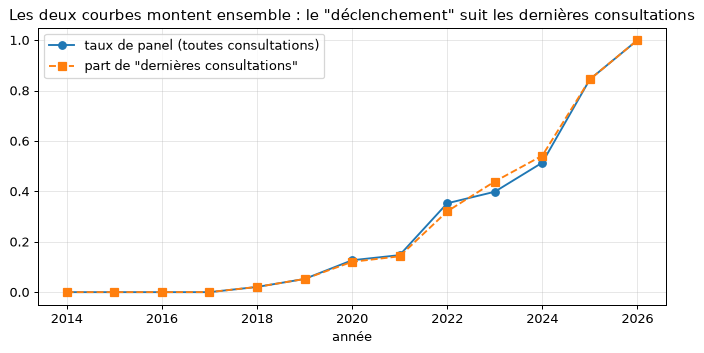

Hypothèse OCULAR → panel :


panel,False,True
prev_flag,,
False,229,87
True,268,115


chi2=0.41, p=0.522


In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yr.index, yr['taux_panel_toutes'], 'o-', label='taux de panel (toutes consultations)')
ax.plot(yr.index, yr['part_dernieres'], 's--', label='part de "dernières consultations"')
ax.set_xlabel('année'); ax.legend(); ax.set_title('Les deux courbes montent ensemble : le "déclenchement" suit les dernières consultations'); plt.show()

# test de l'hypothèse OCULAR de l'exploration initiale : un OCULAR atypique/inconclusif à la visite précédente déclenche-t-il le panel ?
oc = obs[obs.observation_code == 'OCULAR'].groupby('encounter_number')['text_value'].first()
e['ocular_flag'] = e['encounter_number'].map(oc).isin(['atypical', 'inconclusive'])
e['has_ocular'] = e['encounter_number'].isin(oc.index)
e['prev_flag'] = e.groupby('patient_number')['ocular_flag'].shift(1); e['prev_has'] = e.groupby('patient_number')['has_ocular'].shift(1)
t = e[(e.prev_has == True)]
ct = pd.crosstab(t['prev_flag'], t['panel']); chi2, p, *_ = stats.chi2_contingency(ct)
print('Hypothèse OCULAR → panel :'); display(ct); print(f'chi2={chi2:.2f}, p={p:.3f}')

**Conclusion (corrige l'exploration initiale).**
* Les 8 codes sont rattachés à la **dernière consultation de chaque patient** (même proportion proche de 95 %) ; les exceptions sont quelques patients dont la consultation de bilan n'est pas la dernière.
* La hausse temporelle est un **effet de structure** : les dernières consultations de patients sont de plus en plus nombreuses dans les années récentes (`part_dernieres`), et ce sont elles qui portent le panel. **Parmi les dernières consultations, le taux de panel est stable** (colonne `taux_panel_parmi_dernieres`).
* L'hypothèse « OCULAR atypique à la visite précédente déclenche le panel » est **rejetée** (p élevée), ce qui confirme l'exploration initiale.
* **Conséquence méthodologique** : on ne peut pas lire une évolution temporelle dans ces variables. Elles sont des **mesures de bilan unique** par patient, on les compare **entre patients** et non dans le temps. C'est ce que fait la suite.

## 7. Signaux cardiaques : détecter un double rythme 

44 enregistrements de 12 à 30 secondes, 2 canaux (`channel_a`, `channel_b`), **96 925 échantillons**. Les notes parlent de « deux sources partiellement indépendantes ».

**Raisonnement.** Deux canaux d'un même cœur battent **au même rythme** (corrélés, mêmes intervalles RR). Si les canaux ont **chacun un rythme régulier mais des périodes différentes**, il y a deux sources. Il faut distinguer cela de deux fausses pistes :
* **bruit/artefact sur un canal** : un canal est irrégulier (intervalles très variables) ;
* **arythmie synchrone** : les deux canaux sont irréguliers *mais au même rythme*.

Méthode : détection des pics R par canal (`find_peaks`), intervalles inter-battements (IBI), **coefficient de variation** (régularité) et **rapport des périodes** A/B.

In [13]:
# 1) contrôle d'intégrité des signaux
cnt = smp.groupby('recording_id').size()
chk = rec.set_index('recording_id').assign(n_reel=cnt)
print('sample_count ≠ nombre d\'échantillons réels :', int((chk['sample_count'] != chk['n_reel']).sum()),
      '| durée × fréquence ≠ sample_count :', int((chk['duration_seconds'] * chk['sampling_rate_hz'] != chk['sample_count']).sum()),
      '| enregistrements sans échantillons :', int(chk['n_reel'].isna().sum()))

# 2) caractérisation de chaque enregistrement
def analyse(rid):
    r = rec.set_index('recording_id').loc[rid]
    d = smp[smp.recording_id == rid].sort_values('time_ms')
    out = {'recording_id': rid, 'patient_number': r['patient_number'], 'contexte': r['recording_context'],
           'interp_auto': r['automated_interpretation'], 'note_code': r['recording_notes_code']}
    xa, xb = (d[f'channel_{c}_normalized'].to_numpy() for c in 'ab')
    for ch, x in zip('ab', (xa, xb)):
        x = x - np.median(x)
        pk, _ = find_peaks(x, height=0.9, distance=max(1, int(350 / r['sampling_interval_ms'])))
        ibi = np.diff(d['time_ms'].to_numpy()[pk])
        out[f'beats_{ch}'] = len(pk); out[f'ibi_{ch}'] = ibi.mean() if len(ibi) else np.nan
        out[f'cv_{ch}'] = ibi.std() / ibi.mean() if len(ibi) > 2 else np.nan
    out['ratio_AB'] = out['ibi_a'] / out['ibi_b']
    out['corr_AB'] = np.corrcoef(xa, xb)[0, 1]
    return out

sig = pd.DataFrame([analyse(r) for r in rec['recording_id']])
REG = 0.05  # seuil de régularité : CV < 5 % (le rythme sinusal régulier a un CV ≈ 2 %)
sig['regulier_a'] = sig.cv_a < REG; sig['regulier_b'] = sig.cv_b < REG
sig['rythmes_differents'] = (sig.ratio_AB - 1).abs() > 0.05
def categorie(r):
    if r.regulier_a and r.regulier_b and r.rythmes_differents: return '1. DOUBLE RYTHME (2 sources régulières)'
    if r.regulier_a ^ r.regulier_b:                           return '2. bruit / artefact sur un canal'
    if (not r.regulier_a) and (not r.regulier_b):             return '3. arythmie (2 canaux irréguliers)'
    return '4. rythme unique régulier'
sig['catégorie'] = sig.apply(categorie, axis=1)
print(sig['catégorie'].value_counts().sort_index().to_string())
cols = ['recording_id', 'patient_number', 'contexte', 'interp_auto', 'ibi_a', 'ibi_b', 'ratio_AB', 'cv_a', 'cv_b', 'corr_AB', 'catégorie']
display(sig.sort_values(['catégorie', 'ratio_AB'])[cols].round(3).query("catégorie != '4. rythme unique régulier'"))

sample_count ≠ nombre d'échantillons réels : 0 | durée × fréquence ≠ sample_count : 0 | enregistrements sans échantillons : 0
catégorie
1. DOUBLE RYTHME (2 sources régulières)     8
2. bruit / artefact sur un canal            8
3. arythmie (2 canaux irréguliers)          7
4. rythme unique régulier                  21


,recording_id,patient_number,contexte,interp_auto,ibi_a,ibi_b,ratio_AB,cv_a,cv_b,corr_AB,catégorie
3,CRD-410016,PAT-31115,rest,inconclusive,696.000,745.474,0.934,0.016,0.016,0.366,1. DOUBLE RYTHME (2 sources régulières)
4,CRD-410014,PAT-31233,rest,complex,807.238,665.280,1.213,0.012,0.014,0.386,1. DOUBLE RYTHME (2 sources régulières)
2,CRD-410025,PAT-31040,rest,review_required,752.000,605.333,1.242,0.014,0.022,0.360,1. DOUBLE RYTHME (2 sources régulières)
0,CRD-410031,PAT-31162,rest,complex,859.167,684.375,1.255,0.013,0.019,0.353,1. DOUBLE RYTHME (2 sources régulières)
1,CRD-410019,PAT-31162,technical_repeat,irregular,853.529,679.524,1.256,0.018,0.023,0.346,1. DOUBLE RYTHME (2 sources régulières)
7,CRD-410022,PAT-31037,rest,inconclusive,848.750,617.727,1.374,0.012,0.021,0.471,1. DOUBLE RYTHME (2 sources régulières)
6,CRD-410005,PAT-31065,technical_repeat,review_required,895.312,604.792,1.480,0.017,0.019,0.361,1. DOUBLE RYTHME (2 sources régulières)
5,CRD-410038,PAT-31065,rest,irregular,900.800,605.474,1.488,0.018,0.020,0.397,1. DOUBLE RYTHME (2 sources régulières)
43,CRD-410028,PAT-31211,technical_repeat,inconclusive,824.348,1395.385,0.591,0.020,0.692,0.469,2. bruit / artefact sur un canal
32,CRD-410036,PAT-31231,post_exercise,review_required,1055.619,1232.444,0.857,0.310,0.028,0.376,2. bruit / artefact sur un canal


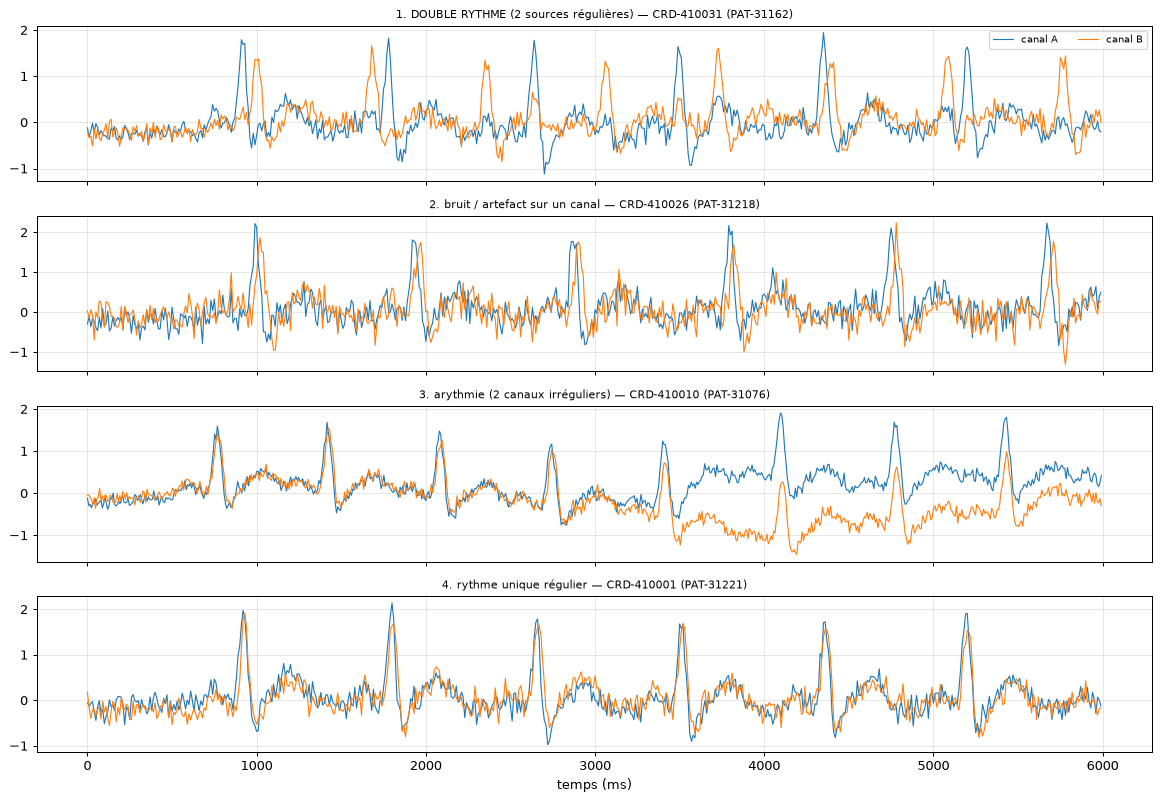

Patients avec double rythme : ['PAT-31037', 'PAT-31040', 'PAT-31065', 'PAT-31115', 'PAT-31162', 'PAT-31233']
Enregistrements concernés : [['CRD-410031', 'PAT-31162', 'rest'], ['CRD-410019', 'PAT-31162', 'technical_repeat'], ['CRD-410025', 'PAT-31040', 'rest'], ['CRD-410016', 'PAT-31115', 'rest'], ['CRD-410014', 'PAT-31233', 'rest'], ['CRD-410038', 'PAT-31065', 'rest'], ['CRD-410005', 'PAT-31065', 'technical_repeat'], ['CRD-410022', 'PAT-31037', 'rest']]


In [14]:
# Visualisation : un exemple par catégorie
ex = {c: sig[sig['catégorie'] == c].iloc[0]['recording_id'] for c in sorted(sig['catégorie'].unique())}
fig, axes = plt.subplots(len(ex), 1, figsize=(13, 9), sharex=True)
for ax, (c, rid) in zip(axes, ex.items()):
    d = smp[(smp.recording_id == rid) & (smp.time_ms < 6000)]
    ax.plot(d.time_ms, d.channel_a_normalized, lw=.9, label='canal A'); ax.plot(d.time_ms, d.channel_b_normalized, lw=.9, label='canal B')
    ax.set_title(f"{c} — {rid} ({sig.set_index('recording_id').loc[rid, 'patient_number']})", fontsize=9)
axes[0].legend(ncol=2, fontsize=8); axes[-1].set_xlabel('temps (ms)'); plt.tight_layout(); plt.show()

dual_pat = sorted(sig[sig['catégorie'].str.startswith('1.')]['patient_number'].unique())
print('Patients avec double rythme :', dual_pat)
print('Enregistrements concernés :', sig[sig['catégorie'].str.startswith('1.')][['recording_id', 'patient_number', 'contexte']].values.tolist())

**.**
* **8 enregistrements, 6 patients** (`PAT-31162` ×2, `PAT-31065` ×2, `PAT-31040`, `PAT-31115`, `PAT-31233`, `PAT-31037`) ont **deux sources régulières à périodes différentes** (rapport A/B de 0,93 à 1,49), alors que chaque canal reste très régulier (CV ≈ 2 %). Les enregistrements répétés (`technical_repeat`) **conservent** le double rythme, ce qui exclut un incident ponctuel, conformément aux notes.
* Les **fausses pistes** sont bien identifiées : bruit sur un seul canal (`PAT-31080`, `31130`, `31155`, `31211`…) et arythmies synchrones (`PAT-31020`, `31008`, `31057`, `31209`, `31059`) où les deux canaux ont le **même** rythme.
* L'**interprétation automatique** de l'appareil (`interp_auto`) ne sépare pas ces cas (« complex », « irregular », « inconclusive », « review_required » sont mélangés), ce qui justifie notre analyse du signal brut.
* Le double rythme se lit sur le rapport des périodes : `PAT-31115` (0,93) est le cas le plus proche d'un rythme unique, ce qui justifie un seuil explicite (5 %) plutôt qu'un clustering des enregistrements.
* Limite : seuls 44 patients ont un enregistrement. Un patient **sans** enregistrement ne peut pas être confirmé ni infirmé par ce moyen.

## 8. Repérer le groupe atypique : représentation, règle à 5 critères, PCA, K-means

### 8.1 Choix de représentation et de métrique

* **Objet comparé** : le patient, décrit par **13 variables** physiologiques numériques (pouls, thorax, balancement, équilibre, oculaire, identification, démarche).
* **Métrique** : distance **euclidienne** (données numériques continues). Le **cosinus** n'est pas adapté (on veut tenir compte de l'amplitude, pas seulement de la direction), ni Hamming/Jaccard (pas de données binaires ou d'ensembles).
* **Échelles** : unités très différentes (bpm, index 0-100, degrés), donc **standardisation** ($z=(x-\mu)/\sigma$) plutôt que Min-Max, car Min-Max serait écrasé par les valeurs extrêmes qui sont précisément ce que l'on cherche. `binoc` (ordinale 0-1-2) est traitée comme numérique, comme le cours le permet pour une catégorie ordonnée.
* **Dimension** : 13 variables pour 240 patients, ce qui est raisonnable (pas de malédiction de la dimension sévère). On vérifie par une **PCA** que l'information tient en peu de dimensions.
* **Redondance** : `n_discordant` est **dérivée** de `pulse_gap` ; On la **garde** (c'est le signal que l'appareil lui-même a levé) mais on **teste l'effet de son retrait** en §8.4.

In [15]:
PHENO = ['pulse_gap', 'n_discordant', 'THORVIB', 'THORPEAK', 'LATSWAY', 'BALANCE', 'ocular_atyp', 'binoc',
         'CAMMATCH', 'IDCONS', 'THERMQUAL', 'eye_asym', 'GAITSYM']
X = F[PHENO].copy()
Z = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=PHENO)
print('Moyennes ≈ 0 :', Z.mean().abs().max().round(6), '| écarts-types = 1 :', Z.std(ddof=0).round(2).unique())

Moyennes ≈ 0 : 0.0 | écarts-types = 1 : [1.]


### 8.2 Définition opérationnelle du « profil complet » : règle à 5 critères

Les notes cliniques décrivent **cinq familles de signes** qui doivent se retrouver **ensemble** chez un même patient :

| # | Critère | Traduction chiffrée |
|---|---|---|
| 1 | Discordance pouls apical / périphérique | `n_discordant ≥ 3` (flag système `discordant` répété) |
| 2 | Signal thoracique secondaire | `THORPEAK` au-dessus du 90ᵉ centile **ou** `THORVIB` à z robuste > 2,5 |
| 3 | Balancement latéral **avec équilibre préservé** | z robuste `LATSWAY` > 1,8 **et** `BALANCE` ≥ médiane |
| 4 | Suivi oculaire atypique | ≥ 50 % de suivis `atypical` **ou** `binoc` = atypique |
| 5 | Incohérence d'identification / thermique | z robuste < −2 sur `CAMMATCH`, `IDCONS` ou `THERMQUAL` |



In [16]:
def robust_z(s):
    m = s.median(); mad = (s - m).abs().median() * 1.4826
    return (s - m) / mad

def criteres(F, k=1.0, min_disc=3):
    C = pd.DataFrame(index=F.index)
    C['c1_pouls']    = F['n_discordant'] >= min_disc
    C['c2_thorax']   = (F['THORPEAK'] > F['THORPEAK'].quantile(.90)) | (robust_z(F['THORVIB']) > 2.5 * k)
    C['c3_balancement'] = (robust_z(F['LATSWAY']) > 1.8 * k) & (F['BALANCE'] >= F['BALANCE'].median())
    C['c4_oculaire'] = (F['ocular_atyp'] >= 0.5) | (F['binoc'] == 2)
    C['c5_identite'] = (robust_z(F['CAMMATCH']) < -2 * k) | (robust_z(F['IDCONS']) < -2 * k) | (robust_z(F['THERMQUAL']) < -2 * k)
    C['score'] = C.sum(axis=1)
    return C

C = criteres(F)
print('Distribution du nombre de critères remplis :', C['score'].value_counts().sort_index().to_dict())
CORE = C.index[C['score'] >= 4].tolist()
print(f'\n=> {len(CORE)} patients remplissent au moins 4 critères sur 5 (aucun patient à exactement 3 : coupure nette)')

# sensibilité aux seuils
sens = []
for k in [0.8, 1.0, 1.2, 1.5]:
    for md_ in [2, 3, 4]:
        Ck = criteres(F, k, md_)
        sens.append({'échelle seuils z': k, 'min discordances': md_, 'patients ≥4/5': int((Ck.score >= 4).sum()),
                     'patients =3/5': int((Ck.score == 3).sum()), 'dont dans CORE': int(Ck.index[Ck.score >= 4].isin(CORE).sum())})
display(pd.DataFrame(sens))

Distribution du nombre de critères remplis : {0: 189, 1: 32, 2: 9, 4: 5, 5: 5}

=> 10 patients remplissent au moins 4 critères sur 5 (aucun patient à exactement 3 : coupure nette)


,échelle seuils z,min discordances,patients ≥4/5,patients =3/5,dont dans CORE
0,0.8,2,10,3,10
1,0.8,3,10,1,10
2,0.8,4,9,2,9
3,1.0,2,10,2,10
4,1.0,3,10,0,10
5,1.0,4,9,1,9
6,1.2,2,9,3,9
7,1.2,3,9,1,9
8,1.2,4,8,2,8
9,1.5,2,6,4,6


In [17]:
admin_i = admin.set_index('patient_number')
core_tab = C.loc[CORE].join(F[['n_discordant', 'THORPEAK', 'THORVIB', 'LATSWAY', 'BALANCE', 'ocular_atyp', 'binoc', 'CAMMATCH', 'IDCONS', 'THERMQUAL', 'bio_gap']]) \
            .join(admin_i[['occupation_text', 'home_region', 'registered_sex', 'primary_facility_license']])
core_tab['double_rythme_signal'] = core_tab.index.isin(dual_pat)
core_tab['a_un_enregistrement'] = core_tab.index.isin(rec['patient_number'])
display(core_tab.sort_values('score', ascending=False).round(1))

,c1_pouls,c2_thorax,c3_balancement,c4_oculaire,c5_identite,score,n_discordant,THORPEAK,THORVIB,LATSWAY,BALANCE,ocular_atyp,binoc,CAMMATCH,IDCONS,THERMQUAL,bio_gap,occupation_text,home_region,registered_sex,primary_facility_license,double_rythme_signal,a_un_enregistrement
PAT-31115,True,True,True,True,True,5,3.0,49.1,54.0,69.0,78.5,0.5,2,72.2,71.7,66.5,-4.0,clinical specialist,Valenne Republic,female,FAC-AVL-301,True,True
PAT-31040,True,True,True,True,True,5,5.0,58.1,66.8,75.6,97.4,0.0,2,80.8,71.1,76.8,-8.2,research professional,Valenne Republic,male,FAC-AVL-201,True,True
PAT-31233,True,True,True,True,True,5,4.0,47.1,76.4,63.0,92.2,0.8,2,59.5,36.3,92.5,-1.7,research professional,Valenne Republic,female,FAC-AVL-301,True,True
PAT-31162,True,True,True,True,True,5,3.0,64.9,73.8,61.8,89.9,0.7,2,73.7,68.6,76.4,-6.4,corporate adviser,Valenne Republic,male,FAC-VLN-101,True,True
PAT-31215,True,True,True,True,True,5,6.0,58.1,58.4,68.2,82.4,0.0,2,82.6,78.2,95.8,-5.7,research professional,Avelora Federation,male,FAC-AVL-201,False,False
PAT-31012,True,True,False,True,True,4,3.0,53.8,34.2,46.4,78.7,1.0,0,55.0,85.3,75.9,-1.3,research professional,Kintara Republic,female,FAC-AVL-201,False,False
PAT-31037,True,False,True,True,True,4,5.0,46.4,39.6,69.9,79.4,0.8,2,68.0,66.7,88.1,1.3,research professional,Avelora Federation,female,FAC-VLN-101,True,True
PAT-31065,True,True,False,True,True,4,6.0,55.6,65.8,57.6,61.0,1.0,2,74.1,91.3,70.8,-4.7,clinical specialist,Valenne Republic,male,FAC-VLN-101,True,True
PAT-31086,True,True,False,True,True,4,6.0,78.5,57.4,55.5,74.0,0.0,2,59.2,76.2,86.4,7.1,corporate adviser,Tembara Commonwealth,male,FAC-AVL-301,False,False
PAT-31186,True,True,False,True,True,4,5.0,61.6,60.6,46.0,76.4,0.8,2,81.9,96.7,74.8,-4.3,corporate adviser,Nordhaven Union,male,FAC-VLN-101,False,False


**.**
* La distribution des scores a une **coupure nette** : 189 patients à 0 critère, 32 à 1, 9 à 2, **aucun à 3**, puis **10 patients à 4 ou 5**. Le choix « ≥ 4 » tombe donc dans un vide de la distribution.
* **Sensibilité aux seuils** : le groupe reste de **10 patients** pour des seuils de 0,8 à 1,0 fois les valeurs retenues, passe à 9 à 1,2 fois et à 6 à 1,5 fois (seuils 50 % plus sévères). **La colonne « dont dans CORE » égale toujours la colonne précédente : durcir les seuils retire des patients du groupe mais n'en ajoute jamais d'autres.** Le groupe est donc un noyau stable, sa taille exacte dépend modérément des seuils.
* **L'exploration initiale en détectait 3** (`PAT-31037`, `31065`, `31233`) parce qu'elle exigeait **simultanément** le top 10 % sur trois critères, ce qui est trop strict et ignore 7 patients (nous la rejouons en §9.3).
* **Les 6 patients à double rythme (§7) sont tous dans ce groupe.** Les 4 autres (`PAT-31215`, `31012`, `31086`, `31186`) **n'ont aucun enregistrement cardiaque** : leur profil est complet sur les mesures cliniques, mais le signal ne peut pas les confirmer.

### 8.3 Visualiser : PCA


Variance expliquée par axe (6 premiers) : [0.269 0.117 0.095 0.089 0.08  0.066] | cumul 2 axes : 0.386 | cumul 5 axes : 0.65


,PC1,PC2,PC3
n_discordant,0.45,-0.16,0.22
pulse_gap,0.43,-0.19,0.20
THORPEAK,0.34,-0.14,0.30
IDCONS,-0.31,-0.25,0.15
THORVIB,0.30,-0.03,0.17
ocular_atyp,0.29,0.29,-0.14
CAMMATCH,-0.26,-0.38,0.33
binoc,0.25,0.14,-0.08
LATSWAY,0.25,-0.41,-0.18
THERMQUAL,-0.19,-0.22,0.39


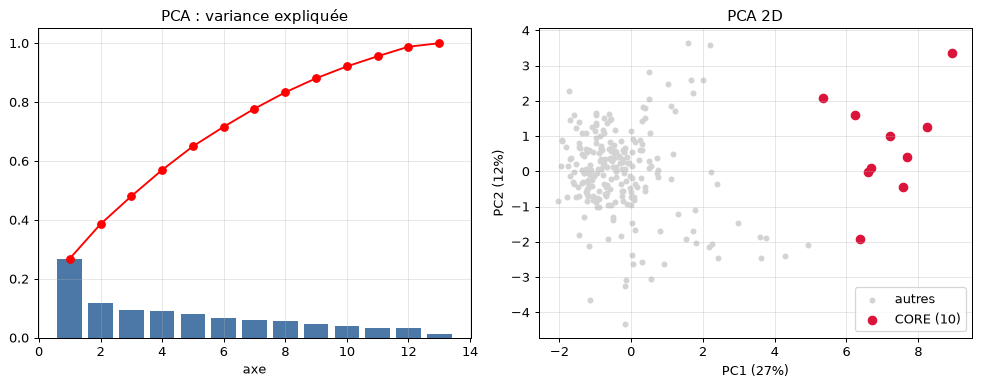

PC1 des 10 patients du CORE : min = 5.4 | PC1 des autres : 99ᵉ centile = 3.7


In [18]:
pca = PCA().fit(Z); evr = pca.explained_variance_ratio_
print('Variance expliquée par axe (6 premiers) :', evr[:6].round(3), '| cumul 2 axes :', evr[:2].sum().round(3), '| cumul 5 axes :', evr[:5].sum().round(3))
load = pd.DataFrame(pca.components_[:3].T, index=PHENO, columns=['PC1', 'PC2', 'PC3'])
display(load.reindex(load['PC1'].abs().sort_values(ascending=False).index).round(2))
P2 = pca.transform(Z)[:, :2]; isc = Z.index.isin(CORE)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].bar(range(1, len(evr) + 1), evr, color='#4c78a8'); axes[0].plot(range(1, len(evr) + 1), np.cumsum(evr), 'ro-'); axes[0].set_title('PCA : variance expliquée'); axes[0].set_xlabel('axe')
axes[1].scatter(P2[~isc, 0], P2[~isc, 1], s=14, c='lightgray', label='autres'); axes[1].scatter(P2[isc, 0], P2[isc, 1], s=45, c='crimson', label='CORE (10)')
axes[1].set_title('PCA 2D'); axes[1].set_xlabel(f'PC1 ({evr[0]:.0%})'); axes[1].set_ylabel(f'PC2 ({evr[1]:.0%})'); axes[1].legend()
plt.tight_layout(); plt.show()
print('PC1 des 10 patients du CORE : min =', P2[isc, 0].min().round(1), '| PC1 des autres : 99ᵉ centile =', np.percentile(P2[~isc, 0], 99).round(1))

**.**
* La variance est étalée sur plusieurs axes (PC1 = 27 %, 5 axes = 65 %) : les variables sont en grande partie indépendantes. **PC1** est portée surtout par les variables de la signature (`n_discordant`, `pulse_gap`, `THORPEAK`, `IDCONS`, `THORVIB`…) et **sépare déjà le groupe CORE** : les 10 patients ont tous une valeur de PC1 supérieure à ~5, alors que la masse des autres patients est entre −2 et +3.
* Quelques patients « autres » s'étalent vers la droite sans atteindre le CORE : ce sont les **profils partiels** (un ou deux signes seulement).

### 8.4 Regroupement : K-means


In [19]:
res = []
for k in range(2, 7):
    km_ = KMeans(k, n_init=30, random_state=SEED).fit(Z)
    lab = pd.Series(km_.labels_, index=Z.index); main = lab[CORE].value_counts().index[0]
    res.append({'k': k, 'silhouette': round(silhouette_score(Z, km_.labels_), 3), 'CORE dans le même cluster': int((lab[CORE] == main).sum()),
                'taille de ce cluster': int((lab == main).sum())})
display(pd.DataFrame(res))

K = 3
km = KMeans(K, n_init=50, random_state=SEED).fit(Z); lab_km = pd.Series(km.labels_, index=Z.index)
main_k = lab_km[CORE].value_counts().index[0]
print(f'K-means k={K} : tailles des clusters {np.bincount(km.labels_).tolist()} | CORE dans le cluster {main_k} : {int((lab_km[CORE] == main_k).sum())}/10, taille du cluster {int((lab_km == main_k).sum())}')

# sensibilité à l'initialisation (limite connue de K-means) : 20 initialisations simples
runs = [pd.Series(KMeans(K, n_init=1, random_state=s).fit_predict(Z), index=Z.index) for s in range(1, 21)]
together = [r for r in runs if r[CORE].nunique() == 1]
iso = sum(1 for r in together if (r == r[CORE].iloc[0]).sum() == 10)
sizes = [int((r == r[CORE].iloc[0]).sum()) for r in together]
print(f'Initialisation unique : CORE groupé dans {len(together)}/20 essais (taille médiane du cluster : {int(np.median(sizes))}) ; cluster de exactement 10 dans {iso}/20 ; avec n_init=50 : retrouvé.')

# robustesse : sans la variable dérivée n_discordant
Zr = pd.DataFrame(StandardScaler().fit_transform(F[[c for c in PHENO if c != 'n_discordant']]), index=Z.index)
kr = pd.Series(KMeans(K, n_init=50, random_state=SEED).fit_predict(Zr), index=Z.index); mk = kr[CORE].value_counts().index[0]
print(f'Sans n_discordant : {int((kr[CORE]==mk).sum())}/10 du CORE dans un cluster de {int((kr==mk).sum())} patients')

,k,silhouette,CORE dans le même cluster,taille de ce cluster
0,2,0.413,10,24
1,3,0.305,10,10
2,4,0.103,10,10
3,5,0.120,10,10
4,6,0.101,10,10


K-means k=3 : tailles des clusters [214, 10, 16] | CORE dans le cluster 1 : 10/10, taille du cluster 10
Initialisation unique : CORE groupé dans 20/20 essais (taille médiane du cluster : 17) ; cluster de exactement 10 dans 1/20 ; avec n_init=50 : retrouvé.
Sans n_discordant : 10/10 du CORE dans un cluster de 16 patients


**.**
* **k=3 est le plus petit *k* qui isole le CORE seul** : un cluster de **exactement 10 patients, tous dans le CORE** (silhouette 0,31). Pour *k*=2 la silhouette est plus haute (0,41) mais le cluster contient 24 patients (le CORE et 14 profils partiels) ; pour *k* de 3 à 6 le CORE reste groupé.
* **Sensibilité à l'initialisation** (limite vue en cours) : avec une seule initialisation aléatoire, le CORE reste groupé mais dans un cluster plus gros (médiane 17) ; le cluster de exactement 10 n'apparaît que dans 1 cas sur 20. D'où `n_init=50`.
* **Variable dérivée** : sans `n_discordant`, le CORE reste détecté mais dans un cluster de 16 patients, donc **moins pur**. Cette variable apporte une information utile (le signal levé par l'appareil) : la garder est un choix assumé.
* Les 230 autres patients n'ont pas de structure en groupes nette ; le seul groupe net est l'îlot de 10.

## 9. Détection d'anomalies

### 9.1 Pourquoi un z-score robuste (médiane/MAD) et pas le z-score classique ?

Le z-score classique utilise une moyenne et un écart-type **tirés par les valeurs extrêmes elles-mêmes** : quand les anomalies sont nombreuses ou fortes, elles se « masquent » (cours : un retrait de 70 000 $ n'était pas détecté à z = 2,45).

In [20]:
def flags_univ(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    f_iqr = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    f_z = ((s - s.mean()) / s.std()).abs() > 3
    f_mz = (0.6745 * (s - s.median()) / ((s - s.median()).abs().median())).abs() > 3.5
    return f_iqr, f_z, f_mz

rows = []
for c in ['pulse_gap', 'THORPEAK', 'LATSWAY', 'IDCONS']:
    a, b, m = flags_univ(F[c])
    rows.append({'variable': c, 'IQR': int(a.sum()), 'IQR ∩ CORE': int(a[CORE].sum()), 'z>3': int(b.sum()), 'z ∩ CORE': int(b[CORE].sum()),
                 'z modifié>3.5': int(m.sum()), 'z modifié ∩ CORE': int(m[CORE].sum())})
display(pd.DataFrame(rows))

,variable,IQR,IQR ∩ CORE,z>3,z ∩ CORE,z modifié>3.5,z modifié ∩ CORE
0,pulse_gap,18,9,7,4,12,7
1,THORPEAK,4,1,1,1,1,1
2,LATSWAY,13,4,2,0,2,0
3,IDCONS,12,7,5,3,8,5


**.** Aucune variable prise seule ne caractérise le groupe : la meilleure (IQR sur `pulse_gap`) en retrouve 9 sur 10 mais signale 18 patients, le z modifié en retrouve 7 sur 12 signalés. Le **z-score classique signale moins de patients** que l'IQR ou le z modifié sur `pulse_gap` et `IDCONS` (7 contre 12-18, 5 contre 8-12) : c'est l'effet de masque, qui justifie le **z robuste** choisi dans la règle du §8.2. Limite : ces méthodes regardent **une variable à la fois**, alors que l'anomalie est **conjointe** : il faut une méthode multivariée.

### 9.2 Isolation Forest (vérification multivariée indépendante de la règle)

**Pourquoi Isolation Forest ?** Aucune hypothèse de loi, rapide, adapté à 13 variables ; il isole les points qu'il suffit de peu de coupures aléatoires pour séparer. On ne l'alimente **pas** avec la règle du §8.2 : c'est un contrôle indépendant.

In [21]:
S = pd.DataFrame(index=Z.index)
S['IsolationForest'] = -IsolationForest(n_estimators=500, random_state=SEED).fit(Z).score_samples(Z)   # plus grand = plus anormal
S['rang_IF'] = S['IsolationForest'].rank(ascending=False)
admin_i = admin.set_index('patient_number')
top = S.sort_values('rang_IF').head(15).join(C['score']).join(admin_i['occupation_text'])
top['CORE'] = top.index.isin(CORE)
print(f"CORE dans le top 10 : {int(S.nsmallest(10, 'rang_IF').index.isin(CORE).sum())}/10 | dans le top 15 : {int(S.nsmallest(15, 'rang_IF').index.isin(CORE).sum())}/10")
display(top[['IsolationForest', 'rang_IF', 'score', 'CORE', 'occupation_text']].round(2))

CORE dans le top 10 : 9/10 | dans le top 15 : 10/10


,IsolationForest,rang_IF,score,CORE,occupation_text
PAT-31065,0.68,1.0,4,True,clinical specialist
PAT-31233,0.68,2.0,5,True,research professional
PAT-31162,0.64,3.0,5,True,corporate adviser
PAT-31037,0.63,4.0,4,True,research professional
PAT-31086,0.63,5.0,4,True,corporate adviser
PAT-31115,0.61,6.0,5,True,clinical specialist
PAT-31186,0.60,7.0,4,True,corporate adviser
PAT-31040,0.60,8.0,5,True,research professional
PAT-31152,0.60,9.0,1,False,small-business owner
PAT-31012,0.59,10.0,4,True,research professional


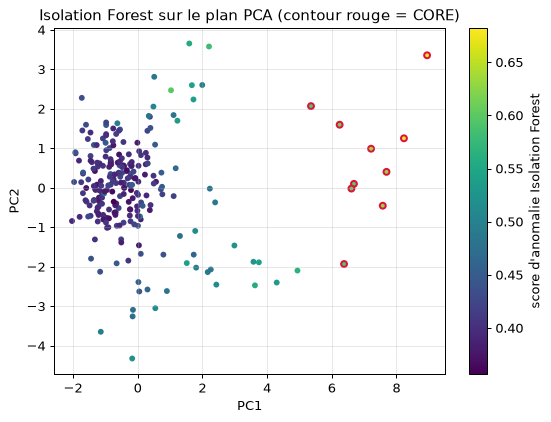

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(P2[:, 0], P2[:, 1], c=S['IsolationForest'], cmap='viridis', s=22, edgecolor=np.where(isc, 'crimson', 'none'), linewidth=1.6)
plt.colorbar(sc, label='score d\'anomalie Isolation Forest'); ax.set_title('Isolation Forest sur le plan PCA (contour rouge = CORE)'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); plt.show()

**.**
* **9 patients du CORE sont dans le top 10** d'Isolation Forest (10 dans le top 15), sans que la méthode ait vu la règle du §8.2 : deux approches de nature différente (règle clinique et isolement aléatoire) **convergent**.
* Les patients du top 15 hors CORE ont **1 ou 2 critères** : ce sont des **profils partiels**. Un outlier statistique n'est pas une anomalie métier : le patient peut être extrême sur une variable sans présenter la **signature cumulée**.
* Pourquoi pas LOF ou ABOD ? LOF détecte surtout les points *localement* isolés (les profils partiels) et ne place que 3 patients du CORE dans son top 10 : le CORE forme un petit îlot dense de 10 points. ABOD, conçu pour les très grandes dimensions, n'apporte rien de plus à 13 variables.

### 9.3 Rejouer la règle de l'exploration initiale

L'exploration initiale sélectionnait les patients avec `|pulse_gap_rest|` > centile 90, `LATSWAY` > centile 90 **et** OCULAR `atypical` à la fois. On reproduit exactement ce filtre pour mesurer ce qu'il manque.

In [23]:
q = lambda s, p: s.quantile(p)
init_rule = (F['pulse_gap_rest'].abs() > q(F['pulse_gap_rest'].abs(), .9)) & (F['LATSWAY'] > q(F['LATSWAY'], .9)) & (F['ocular_atyp'] > 0)
print('Règle initiale (3 critères au 90ᵉ centile simultanément) :', F.index[init_rule].tolist())
print(f'→ rappel sur le CORE : {int(init_rule[CORE].sum())}/10 ; précision : {int(init_rule[CORE].sum())}/{int(init_rule.sum())}')
print('Patients du CORE manqués :', [p for p in CORE if not init_rule[p]])
# pourquoi : combien de patients du CORE dépassent chaque seuil ?
th = pd.DataFrame({'|pulse_gap_rest| > P90': (F['pulse_gap_rest'].abs() > q(F['pulse_gap_rest'].abs(), .9))[CORE],
                   'LATSWAY > P90': (F['LATSWAY'] > q(F['LATSWAY'], .9))[CORE], 'ocular atypique': (F['ocular_atyp'] > 0)[CORE]})
display(th.assign(**{'nb seuils franchis': th.sum(axis=1)}))

Règle initiale (3 critères au 90ᵉ centile simultanément) : ['PAT-31037', 'PAT-31065', 'PAT-31233']
→ rappel sur le CORE : 3/10 ; précision : 3/3
Patients du CORE manqués : ['PAT-31012', 'PAT-31040', 'PAT-31086', 'PAT-31115', 'PAT-31162', 'PAT-31186', 'PAT-31215']


,|pulse_gap_rest| > P90,LATSWAY > P90,ocular atypique,nb seuils franchis
PAT-31012,False,False,True,1
PAT-31037,True,True,True,3
PAT-31040,False,True,False,1
PAT-31065,True,True,True,3
PAT-31086,True,False,False,1
PAT-31115,False,True,True,2
PAT-31162,False,True,True,2
PAT-31186,True,False,True,2
PAT-31215,True,True,False,2
PAT-31233,True,True,True,3


**.** La règle initiale est **correcte mais trop stricte** : un seuil au 90ᵉ centile sur trois variables à la fois ne retient que les patients extrêmes partout. Le groupe est plus large car chaque patient du CORE franchit **la plupart** des seuils mais pas forcément **tous**. Un critère de **cumul** (4 critères sur 5, §8.2) est plus robuste qu'une conjonction de seuils extrêmes.

On retient donc un groupe de **10 patients**, avec deux niveaux de preuve : **6 confirmés par le signal cardiaque**, **4 au profil clinique complet sans enregistrement**.

## 10. Règles d'association (Apriori)

**Objectif.** Quels signes **co-occurrent** chez les patients, et quelles caractéristiques administratives sont associées au profil complet ? Les patients sont des **transactions** ; les **items** sont des états binaires (signe présent, procédure reçue, métier).


In [24]:
def apriori(transactions, min_support):
    """Apriori niveau par niveau avec élagage anti-monotone. Retourne {itemset(frozenset): nb transactions}."""
    n = len(transactions); min_cnt = int(np.ceil(min_support * n))
    cnt = collections.Counter(i for t in transactions for i in t)
    L = {frozenset([i]): c for i, c in cnt.items() if c >= min_cnt}; freq = dict(L); k = 2
    while L:
        prev = list(L); cands = set()
        for a, b in itertools.combinations(prev, 2):
            u = a | b
            if len(u) == k and all(frozenset(s) in L for s in itertools.combinations(u, k - 1)):   # pruning
                cands.add(u)
        cc = collections.Counter()
        for t in transactions:
            for c in cands:
                if c <= t: cc[c] += 1
        L = {c: v for c, v in cc.items() if v >= min_cnt}; freq.update(L); k += 1
    return freq

def rules_from(freq, n, min_conf=0.8, consequents=None):
    out = []
    for iset, c in freq.items():
        if len(iset) < 2: continue
        for r in range(1, len(iset)):
            for X_ in itertools.combinations(iset, r):
                X_ = frozenset(X_); Y = iset - X_
                if consequents and not (Y <= consequents): continue
                conf = c / freq[X_]
                if conf >= min_conf:
                    sx, sy = freq[X_] / n, freq[Y] / n
                    out.append({'X': ' + '.join(sorted(X_)), 'Y': ' + '.join(sorted(Y)), 'support (nb)': c, 'support': c / n, 'confiance': conf,
                                'lift': conf / sy, 'leverage': c / n - sx * sy})
    return pd.DataFrame(out)

# --- transactions : un patient = un ensemble d'items
procs = proc.assign(auth=proc['authorization_class']).query("procedure_code == 'MRP-42'")
mrp_spec = set(procs[procs.auth == 'restricted_specialist']['patient_number'])
tx = {}
for p in F.index:
    t = set()
    if C.loc[p, 'c1_pouls']: t.add('POULS_DISCORDANT')
    if C.loc[p, 'c2_thorax']: t.add('THORAX_ELEVE')
    if C.loc[p, 'c3_balancement']: t.add('BALANCEMENT+EQUILIBRE_OK')
    if C.loc[p, 'c4_oculaire']: t.add('OCULAIRE_ATYPIQUE')
    if C.loc[p, 'c5_identite']: t.add('IDENTIFICATION_BASSE')
    if p in dual_pat: t.add('DOUBLE_RYTHME_SIGNAL')
    if C.loc[p, 'score'] >= 4: t.add('PROFIL_COMPLET')
    if p in mrp_spec: t.add('MRP42_RESTREINT')
    if F.loc[p, 'bio_gap'] < F['bio_gap'].quantile(.10): t.add('AGE_BIO_TRES_BAS(<P10)')
    t.add('METIER=' + F.loc[p, 'occupation_text'])
    tx[p] = t
transactions = list(tx.values()); n_tx = len(transactions)
freq = apriori(transactions, min_support=2 / n_tx)
print(f'{n_tx} transactions | {len(freq)} itemsets fréquents (support ≥ 2 patients) | taille max : {max(len(k) for k in freq)}')

TARGETS = {'PROFIL_COMPLET', 'DOUBLE_RYTHME_SIGNAL'}
R1 = rules_from(freq, n_tx, min_conf=0.9, consequents=TARGETS)
R1 = R1[R1['Y'].isin(TARGETS)]
print('\nRègles (confiance ≥ 0,9) dont la conséquence est un des deux états cibles ; on retient les plus simples (X court) :')
R1['taille X'] = R1['X'].str.count(r'\+') + 1
for y in sorted(TARGETS):
    print(f'\n→ {y}'); display(R1[R1['Y'] == y].sort_values(['taille X', 'lift', 'support (nb)'], ascending=[True, False, False]).head(8).drop(columns=['Y', 'taille X']).round(3))

# règles dont l'antécédent est la procédure restreinte (second groupe, §11)
Rall = rules_from(freq, n_tx, min_conf=0.9)
print('\nRègles (confiance ≥ 0,9) dont l\'antécédent est MRP42_RESTREINT :')
display(Rall[Rall['X'] == 'MRP42_RESTREINT'].sort_values('lift', ascending=False).head(6).round(3))

240 transactions | 392 itemsets fréquents (support ≥ 2 patients) | taille max : 8

Règles (confiance ≥ 0,9) dont la conséquence est un des deux états cibles ; on retient les plus simples (X court) :

→ DOUBLE_RYTHME_SIGNAL


,X,support (nb),support,confiance,lift,leverage
3,METIER=clinical specialist,2,0.008,1.0,40.0,0.008
24,IDENTIFICATION_BASSE + METIER=clinical specialist,2,0.008,1.0,40.0,0.008
27,METIER=clinical specialist + OCULAIRE_ATYPIQUE,2,0.008,1.0,40.0,0.008
29,METIER=clinical specialist + POULS_DISCORDANT,2,0.008,1.0,40.0,0.008
30,METIER=clinical specialist + THORAX_ELEVE,2,0.008,1.0,40.0,0.008
34,METIER=clinical specialist + PROFIL_COMPLET,2,0.008,1.0,40.0,0.008
74,IDENTIFICATION_BASSE + METIER=clinical specialist + POULS_DISCORDANT,2,0.008,1.0,40.0,0.008
77,METIER=clinical specialist + POULS_DISCORDANT + PROFIL_COMPLET,2,0.008,1.0,40.0,0.008



→ PROFIL_COMPLET


,X,support (nb),support,confiance,lift,leverage
1,DOUBLE_RYTHME_SIGNAL,6,0.025,1.0,24.0,0.024
0,METIER=research professional,5,0.021,1.0,24.0,0.020
4,METIER=corporate adviser,3,0.012,1.0,24.0,0.012
2,METIER=clinical specialist,2,0.008,1.0,24.0,0.008
6,OCULAIRE_ATYPIQUE + POULS_DISCORDANT,10,0.042,1.0,24.0,0.040
9,IDENTIFICATION_BASSE + OCULAIRE_ATYPIQUE,10,0.042,1.0,24.0,0.040
13,IDENTIFICATION_BASSE + POULS_DISCORDANT,10,0.042,1.0,24.0,0.040
11,OCULAIRE_ATYPIQUE + THORAX_ELEVE,9,0.038,1.0,24.0,0.036



Règles (confiance ≥ 0,9) dont l'antécédent est MRP42_RESTREINT :


,X,Y,support (nb),support,confiance,lift,leverage
12,MRP42_RESTREINT,AGE_BIO_TRES_BAS(<P10),8,0.033,1.0,10.0,0.03


In [25]:
# Pourquoi le lift ? comparaison : confiance élevée mais lift faible
one = rules_from({k: v for k, v in freq.items() if len(k) <= 2}, n_tx, min_conf=0.0)
sel = one[one['Y'].isin(['PROFIL_COMPLET']) & one['X'].isin(['THORAX_ELEVE', 'POULS_DISCORDANT', 'OCULAIRE_ATYPIQUE', 'IDENTIFICATION_BASSE', 'BALANCEMENT+EQUILIBRE_OK'])]
print('Un seul signe → PROFIL_COMPLET (confiance faible : chaque signe isolé a des explications banales) :')
display(sel.round(3))

occ = one[one['X'].str.startswith('METIER=') & (one['Y'] == 'PROFIL_COMPLET')].sort_values('lift', ascending=False)
print('Métiers → PROFIL_COMPLET :'); display(occ.head(5).round(3))
print('Contre-exemple : le même intitulé avec une autre casse'); display(F.loc[F['occupation_text'].str.lower().isin(['corporate adviser', 'research professional', 'clinical specialist']), ['occupation_text', 'THORPEAK', 'n_discordant']].assign(score=C['score']).sort_values('occupation_text'))

Un seul signe → PROFIL_COMPLET (confiance faible : chaque signe isolé a des explications banales) :


,X,Y,support (nb),support,confiance,lift,leverage
4,IDENTIFICATION_BASSE,PROFIL_COMPLET,10,0.042,0.455,10.909,0.038
6,OCULAIRE_ATYPIQUE,PROFIL_COMPLET,10,0.042,0.588,14.118,0.039
20,THORAX_ELEVE,PROFIL_COMPLET,9,0.038,0.346,8.308,0.033
30,POULS_DISCORDANT,PROFIL_COMPLET,10,0.042,0.500,12.000,0.038
54,BALANCEMENT+EQUILIBRE_OK,PROFIL_COMPLET,6,0.025,0.600,14.400,0.023


Métiers → PROFIL_COMPLET :


,X,Y,support (nb),support,confiance,lift,leverage
17,METIER=research professional,PROFIL_COMPLET,5,0.021,1.0,24.0,0.020
78,METIER=clinical specialist,PROFIL_COMPLET,2,0.008,1.0,24.0,0.008
88,METIER=corporate adviser,PROFIL_COMPLET,3,0.012,1.0,24.0,0.012


Contre-exemple : le même intitulé avec une autre casse


,occupation_text,THORPEAK,n_discordant,score
PAT-31120,Corporate adviser,14.600000,1.0,1
PAT-31065,clinical specialist,55.550000,6.0,4
PAT-31115,clinical specialist,49.100000,3.0,5
PAT-31086,corporate adviser,78.483333,6.0,4
PAT-31162,corporate adviser,64.860000,3.0,5
PAT-31186,corporate adviser,61.580000,5.0,4
PAT-31012,research professional,53.840000,3.0,4
PAT-31037,research professional,46.400000,5.0,4
PAT-31040,research professional,58.075000,5.0,5
PAT-31215,research professional,58.120000,6.0,5


**.**
* Dès **deux signes combinés** (par exemple `OCULAIRE_ATYPIQUE + POULS_DISCORDANT`, 10 patients) la confiance vers `PROFIL_COMPLET` atteint **100 %** (lift = 24, le maximum possible pour un groupe de 10 sur 240), alors qu'un signe **isolé** n'a qu'une confiance de **35 à 60 %** : c'est l'illustration chiffrée du principe « chaque signe seul a une explication banale, leur cumul est rare ». Les 6 patients à **double rythme** ont tous le profil complet (`DOUBLE_RYTHME_SIGNAL → PROFIL_COMPLET`, confiance 100 %), la réciproque étant fausse (6/10) puisque 4 patients n'ont pas d'enregistrement.
* **Le métier** est aussi associé au groupe : les trois intitulés en minuscules `research professional` (5), `corporate adviser` (3) et `clinical specialist` (2) **recouvrent exactement les 10 patients du CORE** (confiance 100 %, lift = 240/10 = 24). **Prudence** : c'est une association, pas une cause. On l'utilise comme **validation externe** (une variable non utilisée pour construire le groupe l'identifie indépendamment), pas comme critère de sélection. Le contre-exemple `Corporate adviser` (casse différente, `PAT-31120`) a un profil **normal** : on ne fusionne donc pas les casses de `occupation_text` (décision du §3).
* Cette convergence est elle-même une piste à signaler aux autres groupes : elle suggère que ces 10 personnes ont été **enregistrées avec un métier standardisé de façade**.
* **Second groupe** : `MRP42_RESTREINT → AGE_BIO_TRES_BAS` a une confiance de 100 % et un lift de 10 (8 patients, soit tous ceux qui reçoivent la procédure en mode `restricted_specialist`), conforme au §11.
* **Pièges de ** : la règle `METIER=clinical specialist → DOUBLE_RYTHME_SIGNAL` a un lift de 40 mais repose sur **2 patients** : un lift élevé avec un support minuscule est fragile (il suffirait d'un patient en plus ou en moins). On regarde donc toujours **support et lift ensemble**.
* Limite : 10 patients, des supports de 2 à 10 patients : les règles sont **descriptives**, sans test statistique de portée générale.

## 11. Un second groupe, distinct : la procédure restreinte `MRP-42` et l'âge biologique

En profilant `clinical_procedures` (§2), un code se détache : **`MRP-42` « Targeted metabolic resilience administration »**, avec deux niveaux d'autorisation (`restricted_specialist` et `research_restricted`). L'exploration initiale ne l'avait pas relié aux autres tables. Question : **qui reçoit cette procédure, et que change-t-elle aux mesures ?**

In [26]:
mrp = proc[proc['procedure_code'] == 'MRP-42']
resume_mrp = mrp.groupby('authorization_class').agg(procédures=('procedure_record_id', 'size'), patients=('patient_number', 'nunique'),
                       soignants=('performing_license_number', 'nunique'), premiere=('performed_time', 'min'), derniere=('performed_time', 'max'))
display(resume_mrp)

grp = pd.Series('aucune MRP-42', index=F.index)
grp[mrp[mrp.authorization_class == 'research_restricted']['patient_number'].unique()] = 'MRP-42 research_restricted'
grp[mrp[mrp.authorization_class == 'restricted_specialist']['patient_number'].unique()] = 'MRP-42 restricted_specialist'
F['groupe_mrp'] = grp
display(F.groupby('groupe_mrp').agg(n=('age', 'size'), age_moyen=('age', 'mean'), bio_gap_moyen=('bio_gap', 'mean'), bio_gap_médian=('bio_gap', 'median'),
                                      bio_gap_min=('bio_gap', 'min'), bio_gap_max=('bio_gap', 'max')).round(1))
els = F[F.groupe_mrp == 'MRP-42 restricted_specialist'].join(mrp[mrp.authorization_class == 'restricted_specialist'].groupby('patient_number').size().rename('nb_MRP42'))
display(els[['occupation_text', 'home_region', 'age', 'BIOAGE', 'bio_gap', 'nb_MRP42']].round(1))

,procédures,patients,soignants,premiere,derniere
authorization_class,,,,,
research_restricted,20,20,7,2019-12-16 10:40:00,2024-04-08 10:40:00
restricted_specialist,30,8,1,2014-07-18 09:05:00,2025-01-31 09:05:00


,n,age_moyen,bio_gap_moyen,bio_gap_médian,bio_gap_min,bio_gap_max
groupe_mrp,,,,,,
MRP-42 research_restricted,20,50.1,-1.1,-0.5,-10.3,14.5
MRP-42 restricted_specialist,8,71.9,-11.3,-12.0,-12.8,-8.8
aucune MRP-42,212,50.4,-1.0,-1.2,-12.6,11.3


,occupation_text,home_region,age,BIOAGE,bio_gap,nb_MRP42
PAT-31044,Senior minister of the Avelora Federation,Avelora Federation,68.2,55.3,-12.4,4
PAT-31074,Executive chair of Nivren Maritime Logistics,Nordhaven Union,75.2,62.3,-11.8,4
PAT-31099,Retired political intermediary and former council president,Avelora Federation,81.0,71.6,-8.8,3
PAT-31119,Chief executive of Solvane Energy Group,Valenne Republic,71.0,58.2,-12.6,4
PAT-31142,Chair of Belen Agro-Industries,Kintara Republic,69.1,58.7,-9.8,3
PAT-31174,Regional governor in the Tembara Commonwealth,Tembara Commonwealth,76.8,65.8,-10.2,4
PAT-31183,Executive director of Ardena Capital Union,Valenne Republic,60.5,47.6,-12.8,3
PAT-31221,Head of government of Kintara Republic,Kintara Republic,73.2,60.0,-12.2,5


Mann-Whitney (restricted_specialist < aucune) : U=31, p=1.51e-10 | taille d'effet de Cohen d = -2.13
Corrélation âge ↔ bio_gap (Spearman) sur tous les patients : -0.08
Contrôle sur l'âge : parmi les patients de plus de 65 ans (n=57)


,count,mean,median
groupe_mrp,,,
MRP-42 research_restricted,5,-2.9,-1.4
MRP-42 restricted_specialist,7,-11.1,-11.8
aucune MRP-42,45,-1.2,-1.1



Anomalies univariées sur bio_gap : IQR=2 (dont 0/8 du groupe), z>3=1, z modifié=0


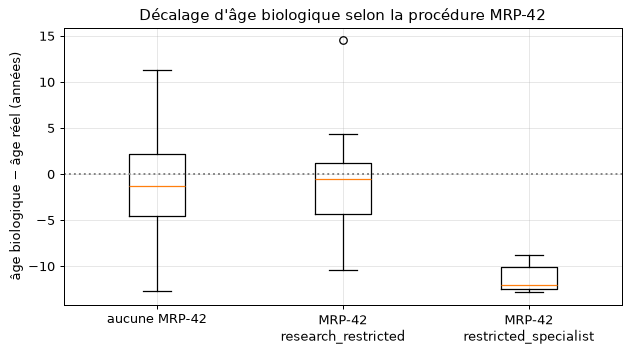

In [27]:
a = F.loc[F.groupe_mrp == 'MRP-42 restricted_specialist', 'bio_gap']; b = F.loc[F.groupe_mrp == 'aucune MRP-42', 'bio_gap']
u, p = stats.mannwhitneyu(a, b, alternative='less')
d = (a.mean() - b.mean()) / np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
print(f'Mann-Whitney (restricted_specialist < aucune) : U={u:.0f}, p={p:.2e} | taille d\'effet de Cohen d = {d:.2f}')
print('Corrélation âge ↔ bio_gap (Spearman) sur tous les patients :', round(F['age'].corr(F['bio_gap'], method='spearman'), 2))
old = F[F.age > 65]
print('Contrôle sur l\'âge : parmi les patients de plus de 65 ans (n=%d)' % len(old)); display(old.groupby('groupe_mrp')['bio_gap'].agg(['count', 'mean', 'median']).round(1))

# le décalage est-il détectable par une méthode univariée ?
for nm, s in [('bio_gap', F['bio_gap'])]:
    f_iqr, f_z, f_mz = flags_univ(s)
    print(f'\nAnomalies univariées sur bio_gap : IQR={int(f_iqr.sum())} (dont {int(f_iqr[els.index].sum())}/8 du groupe), z>3={int(f_z.sum())}, z modifié={int(f_mz.sum())}')

fig, ax = plt.subplots(figsize=(8, 4))
order = ['aucune MRP-42', 'MRP-42 research_restricted', 'MRP-42 restricted_specialist']
ax.boxplot([F.loc[F.groupe_mrp == g, 'bio_gap'] for g in order]); ax.set_xticklabels([o.replace('MRP-42 ', 'MRP-42\n') for o in order])
ax.axhline(0, color='gray', ls=':'); ax.set_ylabel('âge biologique − âge réel (années)'); ax.set_title('Décalage d\'âge biologique selon la procédure MRP-42'); plt.show()

**.**
* Les **8 patients `restricted_specialist`** reçoivent la procédure **3 à 5 fois** (30 procédures au total, toutes par **un seul soignant**, `LIC-VLN-MED-1002`), entre juillet 2014 et janvier 2025. Les **20 patients `research_restricted`** la reçoivent **une seule fois chacun**, entre décembre 2019 et avril 2024, par **7 soignants différents**.
* Les 8 patients ont des **métiers de direction ou de haute responsabilité** (chef de gouvernement, ministre, gouverneur régional, présidents de grands groupes). Ils sont **nettement plus âgés** (âge moyen 72 ans contre 50 pour les autres).
* Leur **âge biologique est ~11 ans inférieur à leur âge réel** (moyenne −11,3 ; de −8,8 à −12,8), contre ≈ −1 pour les autres. Le test de Mann-Whitney est très significatif (p ≈ 1,5·10⁻¹⁰) et la taille d'effet est **très grande** (|d| > 2). Le contrôle **sur les plus de 65 ans** (−11,1 contre −1,2 pour ceux sans MRP-42) et la corrélation âge↔décalage quasi nulle (−0,08) montrent que ce n'est **pas un simple effet d'âge**.
* **Anomalie contextuelle** (Cours 3) : sur la seule variable `bio_gap`, **aucune méthode univariée ne signale ces patients** (IQR : 2 patients signalés dont 0/8 du groupe ; z-score : 1 ; z modifié : 0). La différence n'apparaît qu'en **croisant** la procédure reçue, l'âge et le métier. Une détection univariée l'aurait **manquée** : c'est un cas où un outlier statistique et une anomalie métier **ne coïncident pas**.
* Ce groupe est **distinct** du CORE : aucun des 8 n'a de profil complet (§8.2), les enregistrements disponibles montrent un rythme unique, et la note de `PAT-31099` rejette explicitement l'idée d'une double structure. Ce sont donc **deux phénomènes différents** : un phénotype physiologique rare (CORE) et un traitement réservé à des personnes influentes (MRP-42). Leur **parcours de soins** est lui aussi à part (§12).
* Limite : corrélation ≠ causalité. Le décalage est **compatible** avec un effet de la procédure, mais les données ne permettent pas de l'établir (groupe de 8, pas de comparaison avant/après). Les 20 patients `research_restricted` n'ont, eux, **pas** de décalage (−1,1) : la procédure seule, en une administration, ne suffit pas à l'expliquer.

## 12. Parcours de soins

**Données** : un **journal d'événements** : cas = patient, activité = type de consultation, horodatage = début de la consultation. On compare le parcours du **CORE**, du groupe **MRP-42 `restricted_specialist`** et des **autres** patients.

**Pourquoi se limiter aux fréquences d'activités ?** Le journal est petit (≈ 10 types de consultation, ~1 000 événements, et seulement ~50 pour le CORE) : un Heuristic Miner (dépendances entre activités) serait peu discriminant, et un graphe de similarité entre patients redonnerait le groupe déjà isolé par K-means. Les fréquences d'activités répondent directement à la question : **ces patients sont-ils suivis pour des raisons différentes ?**

In [28]:
log = enc.sort_values(['patient_number', 'encounter_start'])[['patient_number', 'encounter_start', 'encounter_type']].copy()
log['groupe'] = np.where(log.patient_number.isin(CORE), 'CORE', np.where(log.patient_number.isin(els.index), 'MRP-42 restricted_specialist', 'autres'))

# 1) activités propres à chaque groupe
mix = pd.crosstab(log['encounter_type'], log['groupe'], normalize='columns').round(3)
display(mix)
ct = pd.crosstab(log['encounter_type'], log['groupe'].isin(['CORE']))
chi2, p, *_ = stats.chi2_contingency(ct)
print(f'Test du chi² (type de consultation × appartenance au CORE) : chi2={chi2:.1f}, p={p:.1e}')
print('Types de consultation JAMAIS observés chez le CORE :', sorted(set(log['encounter_type']) - set(log.loc[log.groupe == 'CORE', 'encounter_type'])))

groupe,CORE,MRP-42 restricted_specialist,autres
encounter_type,,,
cardiac_assessment,0.291,0.000,0.064
executive_health_review,0.000,0.559,0.064
general_examination,0.000,0.000,0.239
mobility_assessment,0.364,0.000,0.064
occupational_assessment,0.000,0.000,0.231
ocular_assessment,0.218,0.000,0.034
research_procedure,0.000,0.000,0.021
specialist_follow_up,0.127,0.000,0.250
specialist_procedure,0.000,0.441,0.000


Test du chi² (type de consultation × appartenance au CORE) : chi2=184.2, p=6.6e-35
Types de consultation JAMAIS observés chez le CORE : ['executive_health_review', 'general_examination', 'occupational_assessment', 'research_procedure', 'specialist_procedure', 'technical_repeat']


**.**
* Le CORE a un **parcours de soins distinct** : il n'est **jamais** vu en `general_examination`, `occupational_assessment`, `executive_health_review`, procédures de recherche ou de spécialité : uniquement `cardiac_assessment`, `mobility_assessment`, `ocular_assessment` et `specialist_follow_up`. Ce sont **exactement les trois domaines des signes** (rythme, démarche, œil). Le test du chi² est très significatif.
* Autrement dit, ces patients sont **explorés pour leurs signes** et non pour des raisons de routine ou d'emploi : c'est **cohérent** avec un phénotype réel plutôt qu'avec un artefact de saisie.
* Le groupe **MRP-42 `restricted_specialist`** a lui aussi un parcours exclusif : uniquement des `executive_health_review` (56 %) et des `specialist_procedure` (44 %). Les **deux groupes se reconnaissent donc à leur parcours** sans regarder une seule mesure.
* Limite : peu de cas (10 et 8 patients), pas de durées exploitées.

## 13. Synthèse, vérifications d'identité, pistes pour les autres groupes

### 13.1 Tableau de preuves final (un patient du CORE = une ligne)

In [29]:
ev = C.loc[CORE, ['c1_pouls', 'c2_thorax', 'c3_balancement', 'c4_oculaire', 'c5_identite', 'score']].copy()
ev['enregistrement'] = np.where(ev.index.isin(rec['patient_number']), 'oui', 'non')
ev['double_rythme_signal'] = np.where(ev.index.isin(dual_pat), 'OUI', np.where(ev.index.isin(rec['patient_number']), 'non', 'n/a'))
ev['cluster K-means'] = lab_km[ev.index]
ev['rang Isolation Forest'] = S.loc[ev.index, 'rang_IF']
ev['note clinique singulière'] = np.where(ev.index.isin(['PAT-31065', 'PAT-31115', 'PAT-31012']), 'oui', '')
ev = ev.join(admin_i[['occupation_text', 'home_region', 'registered_sex', 'primary_facility_license']]).join(F[['bio_gap']].round(1))
ev['niveau de preuve'] = np.where(ev['double_rythme_signal'] == 'OUI', 'CONFIRMÉ (cliniques + signal)', 'PROBABLE (cliniques seulement)')
display(ev.sort_values(['niveau de preuve', 'score'], ascending=[True, False]))
print(ev['niveau de preuve'].value_counts().to_string())

,c1_pouls,c2_thorax,c3_balancement,c4_oculaire,c5_identite,score,enregistrement,double_rythme_signal,cluster K-means,rang Isolation Forest,note clinique singulière,occupation_text,home_region,registered_sex,primary_facility_license,bio_gap,niveau de preuve
PAT-31040,True,True,True,True,True,5,oui,OUI,1,8.0,,research professional,Valenne Republic,male,FAC-AVL-201,-8.2,CONFIRMÉ (cliniques + signal)
PAT-31115,True,True,True,True,True,5,oui,OUI,1,6.0,oui,clinical specialist,Valenne Republic,female,FAC-AVL-301,-4.0,CONFIRMÉ (cliniques + signal)
PAT-31162,True,True,True,True,True,5,oui,OUI,1,3.0,,corporate adviser,Valenne Republic,male,FAC-VLN-101,-6.4,CONFIRMÉ (cliniques + signal)
PAT-31233,True,True,True,True,True,5,oui,OUI,1,2.0,,research professional,Valenne Republic,female,FAC-AVL-301,-1.7,CONFIRMÉ (cliniques + signal)
PAT-31037,True,False,True,True,True,4,oui,OUI,1,4.0,,research professional,Avelora Federation,female,FAC-VLN-101,1.3,CONFIRMÉ (cliniques + signal)
PAT-31065,True,True,False,True,True,4,oui,OUI,1,1.0,oui,clinical specialist,Valenne Republic,male,FAC-VLN-101,-4.7,CONFIRMÉ (cliniques + signal)
PAT-31215,True,True,True,True,True,5,non,n/a,1,11.0,,research professional,Avelora Federation,male,FAC-AVL-201,-5.7,PROBABLE (cliniques seulement)
PAT-31012,True,True,False,True,True,4,non,n/a,1,10.0,oui,research professional,Kintara Republic,female,FAC-AVL-201,-1.3,PROBABLE (cliniques seulement)
PAT-31086,True,True,False,True,True,4,non,n/a,1,5.0,,corporate adviser,Tembara Commonwealth,male,FAC-AVL-301,7.1,PROBABLE (cliniques seulement)
PAT-31186,True,True,False,True,True,4,non,n/a,1,7.0,,corporate adviser,Nordhaven Union,male,FAC-VLN-101,-4.3,PROBABLE (cliniques seulement)


niveau de preuve
CONFIRMÉ (cliniques + signal)     6
PROBABLE (cliniques seulement)    4


### 13.2 Faux positifs écartés (et pourquoi)


In [30]:
traps = []
traps.append({'piège': 'Note PAT-31099 « dual cardiac structures »', 'verdict': 'écarté', 'raison': 'paragraphe « DIFFERENTIAL NOTE » : hypothèse rejetée ; signal à rythme unique ; 0 critère'})
traps.append({'piège': 'Note PAT-31103 « appearance control / mismatch »', 'verdict': 'écarté', 'raison': 'paragraphe « TECHNICAL NOTE » : écart résolu par calibration ; score = %d critère(s)' % C.loc['PAT-31103', 'score']})
noisy = sig[sig['catégorie'].str.startswith('2.')]
traps.append({'piège': 'Désynchronisation de canaux (%d enregistrements)' % len(noisy), 'verdict': 'écarté', 'raison': 'un canal irrégulier (bruit / artefact), pas deux sources régulières : ' + ', '.join(sorted(noisy.patient_number.str[-5:].unique()))})
arr = sig[sig['catégorie'].str.startswith('3.')]
traps.append({'piège': 'Arythmies (%d enregistrements)' % len(arr), 'verdict': 'écarté', 'raison': 'deux canaux irréguliers ; pour 5 cas sur 7 au MÊME rythme (rapport A/B ≈ 1, corrélation 0,8-0,9) donc une seule source ; les 2 autres (PAT-31063, 31076) sont irréguliers sur les deux canaux : non classables comme double rythme'})
traps.append({'piège': 'Hausse du taux de panel biométrique dans le temps', 'verdict': 'artefact', 'raison': 'le panel suit les dernières consultations de chaque patient (§6)'})
traps.append({'piège': 'Interprétation automatique des enregistrements', 'verdict': 'non fiable', 'raison': 'mélange « complex », « inconclusive », « normal » sur des signaux de nature différente (§7)'})
traps.append({'piège': 'Règle initiale à 3 seuils au 90ᵉ centile', 'verdict': 'trop stricte', 'raison': 'rappel 3/10 (§9.3)'})
display(pd.DataFrame(traps))

,piège,verdict,raison
0,Note PAT-31099 « dual cardiac structures »,écarté,paragraphe « DIFFERENTIAL NOTE » : hypothèse rejetée ; signal à rythme uniqu...
1,Note PAT-31103 « appearance control / mismatch »,écarté,paragraphe « TECHNICAL NOTE » : écart résolu par calibration ; score = 0 cri...
2,Désynchronisation de canaux (8 enregistrements),écarté,"un canal irrégulier (bruit / artefact), pas deux sources régulières : 31080,..."
3,Arythmies (7 enregistrements),écarté,"deux canaux irréguliers ; pour 5 cas sur 7 au MÊME rythme (rapport A/B ≈ 1, ..."
4,Hausse du taux de panel biométrique dans le temps,artefact,le panel suit les dernières consultations de chaque patient (§6)
5,Interprétation automatique des enregistrements,non fiable,"mélange « complex », « inconclusive », « normal » sur des signaux de nature ..."
6,Règle initiale à 3 seuils au 90ᵉ centile,trop stricte,rappel 3/10 (§9.3)


### 13.3 Vérification de la piste « identité publique » citée dans une note

La note `CLN-510025` (`PAT-31065`) affirme que le patient peut être relié « par des attributs administratifs non secrets » à l'identité publique **Elias Voss**. Les attributs de la note sont : *bande de date de naissance, région, adressage « executive health », historique d'établissement, combinaison rare de rôle public et dates de nomination.* **Testons-le** contre le registre public (`officer_filings.csv`), qui appartient à un autre domaine mais est nécessaire pour valider cette affirmation.

In [31]:
off = pd.read_csv('data/public_records/officer_filings.csv')
voss = off[off['full_name'].str.contains('Elias Voss', na=False)].iloc[0]
print('Registre public :', voss[['full_name', 'birth_year_or_age_band', 'nationality_or_region', 'role_title', 'appointment_date', 'filing_status']].to_dict())

def ident_row(p):
    r = admin_i.loc[p]; e_ = enc[enc.patient_number == p]
    return {'patient': p, 'année de naissance': r['date_of_birth'].year, 'sexe': r['registered_sex'], 'région': r['home_region'], 'métier': r['occupation_text'],
            'consultations "executive health office"': int((e_['referral_source'] == 'executive health office').sum()), 'établissement': r['primary_facility_license'],
            'double rythme': p in dual_pat}
cmp = pd.DataFrame([ident_row(p) for p in ['PAT-31065', 'PAT-31162']])
cmp.loc[len(cmp)] = {'patient': 'Voss (registre public)', 'année de naissance': int(voss['birth_year_or_age_band']), 'sexe': 'n/a', 'région': voss['nationality_or_region'],
                     'métier': voss['role_title'], 'consultations "executive health office"': np.nan, 'établissement': 'n/a', 'double rythme': np.nan}
display(cmp)
yob = F.loc[CORE, 'date_of_birth'].dt.year
print('\nAnnée de naissance des 10 patients du CORE :', yob.sort_values().to_dict())
print('Patients du CORE nés entre 1959 et 1964, région Valenne :', [p for p in CORE if 1959 <= yob[p] <= 1964 and 'Valenne' in admin_i.loc[p, 'home_region']])

Registre public : {'full_name': 'Dr. Elias Voss', 'birth_year_or_age_band': '1961', 'nationality_or_region': 'Valennan', 'role_title': 'Executive chair of Meridian BioLogistics', 'appointment_date': '1996-01-01', 'filing_status': 'active'}


,patient,année de naissance,sexe,région,métier,"consultations ""executive health office""",établissement,double rythme
0,PAT-31065,1975,male,Valenne Republic,clinical specialist,1.0,FAC-VLN-101,True
1,PAT-31162,1962,male,Valenne Republic,corporate adviser,1.0,FAC-VLN-101,True
2,Voss (registre public),1961,n/a,Valennan,Executive chair of Meridian BioLogistics,NaN,n/a,NaN



Année de naissance des 10 patients du CORE : {'PAT-31162': 1962, 'PAT-31186': 1969, 'PAT-31040': 1972, 'PAT-31086': 1973, 'PAT-31065': 1975, 'PAT-31215': 1976, 'PAT-31115': 1979, 'PAT-31012': 1981, 'PAT-31233': 1983, 'PAT-31037': 1986}
Patients du CORE nés entre 1959 et 1964, région Valenne : ['PAT-31162']


****
* **L'affirmation de la note ne se vérifie pas sur `PAT-31065`** avec les attributs disponibles : né en **1975**, métier « clinical specialist », alors que le registre indique **1961** et « Executive chair ». L'écart de 14 ans est hors de toute « bande » raisonnable.
* Les deux patients ont **chacun une consultation adressée par `executive health office`** : cet attribut ne les départage pas. Parmi les 10 patients du CORE, **un seul** est né vers 1961-1962 en région Valenne : **`PAT-31162`** (né en 1962, homme, « corporate adviser », statut `inactive`), dont le métier est de plus proche d'un rôle de direction. Il fait aussi partie des patients à double rythme confirmé.
* **Ce n'est pas une preuve.** Les notes le disent elles-mêmes (« Public attribution should not be made from this consultation alone ») et l'archive publique évoque des identités **successives** (alias, dates de naissance incohérentes selon les sources). Nous **signalons deux hypothèses** (`PAT-31065` selon la note, `PAT-31162` selon les attributs mesurables) **à départager avec le groupe Public records**, plutôt que de trancher.

### 13.4 Pistes à transmettre

| Piste | Où la vérifier | Pourquoi |
|---|---|---|
| Hypothèses d'identité `PAT-31065` / `PAT-31162` ↔ Elias Voss (et alias antérieurs) | **Public records** (`officer_filings`, `institutional_memos`, documents d'enquête) | §13.3 |
| `material_reference` (`MTL-aaaa-nnnn`) des procédures `MRP-42` | **Logistics** (`purchase_order_lines`, `goods_receipts`, `shipments`) | Le matériel utilisé pour la procédure peut être tracé jusqu'à un fournisseur |
| Opérateur des établissements : `FAC-VLN-101` et `FAC-AVL-201` par *Asterion Clinical Institute* ; `FAC-AVL-301` par *Threshold Earth Observatory* | **Public records** (`licensed_facilities`, `registered_entities`) | Voir ci-dessous : 31 % des consultations du CORE ont lieu à `FAC-AVL-301` contre 10 % pour les autres, **tendance non significative au niveau des patients** (p = 0,08) |
| Les 8 bénéficiaires `restricted_specialist` (dirigeants) | **Public records** (`public_appointments`) | Retrouver leurs fonctions et dates |

In [32]:
fac = enc.assign(CORE=enc.patient_number.isin(CORE)).groupby(['facility_license_number', 'CORE']).size().unstack(fill_value=0)
fac_pct = (fac / fac.sum()).round(3); fac_pct.columns = ['part des consultations des autres', 'part des consultations du CORE']
display(fac.join(fac_pct))
core_in_301 = enc[enc.patient_number.isin(CORE)].groupby('patient_number')['facility_license_number'].apply(lambda s: (s == 'FAC-AVL-301').any())
oth_in_301 = enc[~enc.patient_number.isin(CORE)].groupby('patient_number')['facility_license_number'].apply(lambda s: (s == 'FAC-AVL-301').any())
tab2 = [[int(core_in_301.sum()), int((~core_in_301).sum())], [int(oth_in_301.sum()), int((~oth_in_301).sum())]]
odds, pf = stats.fisher_exact(tab2)
print(f'Patients ayant au moins une consultation à FAC-AVL-301 : CORE {tab2[0][0]}/10 vs autres {tab2[1][0]}/230 ; Fisher exact p={pf:.3f}')
print('\nExemples de références matériel MRP-42 :', mrp['material_reference'].dropna().head(5).tolist())

,False,True,part des consultations des autres,part des consultations du CORE
facility_license_number,,,,
FAC-AVL-201,277,16,0.274,0.291
FAC-AVL-301,99,17,0.098,0.309
FAC-VLN-101,636,22,0.628,0.400


Patients ayant au moins une consultation à FAC-AVL-301 : CORE 3/10 vs autres 23/230 ; Fisher exact p=0.081

Exemples de références matériel MRP-42 : ['MTL-2016-0002', 'MTL-2018-0003', 'MTL-2020-0004', 'MTL-2022-0005', 'MTL-2024-0006']



### 13.5 Conclusion

Le domaine **Health** contient **deux phénomènes distincts** :

1. **Un phénotype physiologique rare, porté par 10 patients** : discordance pouls apical/périphérique, signal thoracique secondaire, balancement latéral avec équilibre préservé, suivi oculaire atypique, incohérences d'identification. Chez **6** d'entre eux, les signaux cardiaques montrent **deux rythmes réguliers distincts** (double source). Chez les 4 autres, le profil clinique est complet mais **aucun enregistrement ne permet de conclure**. Ce groupe se retrouve par plusieurs méthodes de natures différentes (règle à 5 critères, PCA, K-means, Isolation Forest) et par deux variables **non utilisées** pour le construire (le métier et le parcours de soins).
2. **Une procédure réservée à des dirigeants** (`MRP-42`, `restricted_specialist`, 8 patients) associée à un **âge biologique inférieur d'environ 11 ans** à l'âge réel, avec un parcours de soins exclusif.

Les notes cliniques **s'interdisent de conclure** sur une espèce ou une identité ; nous faisons de même. Nous établissons un **phénotype**, nous le relions à des **pistes** pour les autres domaines, et nous signalons les **faux positifs** et les **limites**.

### 13.6 Limites

* **Petits effectifs** (10 et 8 patients) : les tests statistiques et règles d'association sont **descriptifs**.
* **Seuils** : les critères du §8.2 sont **choisis** (la sensibilité montre une stabilité modérée, pas une absence de choix).
* **Données synthétiques** : le narratif est fictif, donc certaines régularités (métiers, formats) sont des **artefacts de génération** autant que des indices.
* **Quatre patients sans enregistrement** : leur appartenance au phénotype reste **probable** et non confirmée.
* **Pas de validation externe** : sans étiquette de référence, la validité repose sur la **convergence** de méthodes de natures différentes (règle clinique, PCA/K-means, Isolation Forest, signaux).
* **Usage de l'IA** : voir la déclaration en tête de notebook.